In [1]:
# step1_prepare_index_images_kaggle.py
# ---------------------------------------------
# Purpose:
#   - Scan your 3 modality folders (all images)
#   - Build label map (person -> class id)
#   - Create subject-wise train/val/test splits
#   - Save: /kaggle/working/metadata/{label_map.json, splits.json, index.csv}
#
# Run: just execute this cell in Kaggle.

import json
import random
from pathlib import Path
import pandas as pd
import sys

# ---------- CONFIG ----------
# Change ROOT_DIR if your dataset path is different.
ROOT_DIR = Path("/kaggle/input/datasets/mdabujohab/final-gait-dronevideofolder/GEI_Journal_folder")

# Prefer canonical names; fallbacks handled below.
SKELETON_DIRNAME   = "GEI_skeleton_folder"
SILHOUETTE_NAMES   = "GEI_silhoutte_folder"  # handle both
HEATMAP_DIRNAME    = "GEI_heatmap_folder"

IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# ---------- HELPERS ----------
def list_images(p: Path):
    return sorted([f for f in p.glob("*") if f.is_file() and f.suffix.lower() in IMG_EXTS])

def get_person_dirs(modality_root: Path):
    if not modality_root.exists():
        raise FileNotFoundError(f"Missing modality folder: {modality_root}")
    return {d.name: d for d in sorted(modality_root.iterdir()) if d.is_dir()}

def make_label_map(person_ids):
    return {pid: i for i, pid in enumerate(sorted(person_ids))}

def subject_splits(person_ids, train=0.7, val=0.15, test=0.15, seed=1337):
    assert abs((train + val + test) - 1.0) < 1e-6, "train/val/test must sum to 1"
    rng = random.Random(seed)
    pids = sorted(person_ids)
    rng.shuffle(pids)
    n = len(pids)
    n_train = int(round(n * train))
    n_val   = int(round(n * val))
    n_test  = n - n_train - n_val
    return {"train": pids[:n_train],
            "val":   pids[n_train:n_train+n_val],
            "test":  pids[n_train+n_val:]}

def pick_existing(root: Path, names):
    """Return the first existing subfolder from a list of candidate names."""
    if isinstance(names, str):
        p = root / names
        if p.exists():
            return p
        raise FileNotFoundError(f"Folder not found: {p}")
    for name in names:
        p = root / name
        if p.exists():
            return p
    raise FileNotFoundError(f"None of these folders exist under {root}: {names}")

# ---------- MAIN ----------
def main():
    root = ROOT_DIR

    skel_root = pick_existing(root, SKELETON_DIRNAME)
    sil_root  = pick_existing(root, SILHOUETTE_NAMES)  # handles both spellings
    heat_root = pick_existing(root, HEATMAP_DIRNAME)

    # 1) Collect person directories
    skel_dirs = get_person_dirs(skel_root)
    sil_dirs  = get_person_dirs(sil_root)
    heat_dirs = get_person_dirs(heat_root)

    skel_ids = set(skel_dirs.keys())
    sil_ids  = set(sil_dirs.keys())
    heat_ids = set(heat_dirs.keys())

    # Persons present in ALL three modalities
    common_ids = sorted(list(skel_ids & sil_ids & heat_ids))
    missing_any = sorted(list((skel_ids | sil_ids | heat_ids) - set(common_ids)))

    if not common_ids:
        raise RuntimeError(
            "No common person IDs across all modalities. "
            f"Counts — skeleton:{len(skel_ids)}, silhouette:{len(sil_ids)}, heatmap:{len(heat_ids)}. "
            "Check folder names and contents."
        )

    # 2) Build label map
    label_map = make_label_map(common_ids)

    # 3) Summarize per person
    rows = []
    for pid in common_ids:
        n_skel = len(list_images(skel_dirs[pid]))
        n_sil  = len(list_images(sil_dirs[pid]))
        n_heat = len(list_images(heat_dirs[pid]))

        rows.append({
            "person_id": pid,
            "label": label_map[pid],
            "skeleton_dir": str(skel_dirs[pid]),
            "n_skeleton": n_skel,
            "silhouette_dir": str(sil_dirs[pid]),
            "n_silhouette": n_sil,
            "heatmap_dir": str(heat_dirs[pid]),
            "n_heatmap": n_heat,
        })

    df = pd.DataFrame(rows).sort_values("label").reset_index(drop=True)

    # 4) Subject-exclusive splits (identity-safe)
    splits = subject_splits(common_ids, train=0.70, val=0.15, test=0.15, seed=1337)
    pid2split = {pid: split for split, lst in splits.items() for pid in lst}
    df["split"] = df["person_id"].map(pid2split)

    # 5) Save under /kaggle/working (writable)
    meta_dir = Path("/kaggle/working/metadata")
    meta_dir.mkdir(parents=True, exist_ok=True)

    (meta_dir / "label_map.json").write_text(json.dumps(label_map, indent=2))
    (meta_dir / "splits.json").write_text(json.dumps(splits, indent=2))
    df.to_csv(meta_dir / "index.csv", index=False)

    # 6) Summary
    print("=== Dataset Summary ===")
    print(f"Root: {root}")
    print(f"Persons with all 3 modalities: {len(common_ids)}")
    if missing_any:
        print(f"Persons missing at least one modality: {len(missing_any)} (e.g., {missing_any[:8]})")
    print("\nCounts by split:")
    print(df["split"].value_counts())
    print("\nFirst rows:")
    print(df.head())
    print(f"\nSaved to: {meta_dir}")

# Kaggle/Colab fix: ignore injected -f arguments
if __name__ == "__main__":
    sys.argv = sys.argv[:1]
    main()


=== Dataset Summary ===
Root: /kaggle/input/datasets/mdabujohab/final-gait-dronevideofolder/GEI_Journal_folder
Persons with all 3 modalities: 50

Counts by split:
split
train    35
val       8
test      7
Name: count, dtype: int64

First rows:
  person_id  label                                       skeleton_dir  \
0  person00      0  /kaggle/input/datasets/mdabujohab/final-gait-d...   
1  person01      1  /kaggle/input/datasets/mdabujohab/final-gait-d...   
2  person02      2  /kaggle/input/datasets/mdabujohab/final-gait-d...   
3  person03      3  /kaggle/input/datasets/mdabujohab/final-gait-d...   
4  person04      4  /kaggle/input/datasets/mdabujohab/final-gait-d...   

   n_skeleton                                     silhouette_dir  \
0         191  /kaggle/input/datasets/mdabujohab/final-gait-d...   
1         242  /kaggle/input/datasets/mdabujohab/final-gait-d...   
2         221  /kaggle/input/datasets/mdabujohab/final-gait-d...   
3         221  /kaggle/input/datasets/mdabujo

In [2]:
# step2_dataloaders.py
# ----------------------------------------------------------
# Multi-modal Dataset (images-only):
#   - Skeleton: single image -> 2D CNN input (C,H,W)
#   - Silhouette: clip of T images -> 3D CNN input (C,T,H,W)
#   - Heatmap:   clip of T images -> 3D CNN input (C,T,H,W)
#
# Reads metadata from /kaggle/working/metadata/{index.csv,label_map.json}
# which you created in Step 1.

import json, math, random
from pathlib import Path
from typing import List, Dict, Tuple

import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T

# ---------------- Config ----------------
META_DIR = Path("/kaggle/working/metadata")   # Step-1 outputs live here
INDEX_CSV = META_DIR / "index.csv"
LABEL_MAP_JSON = META_DIR / "label_map.json"

SEED = 1337
random.seed(SEED)

# Image/clip settings
IMG_SIZE = 224       # resize shorter side then center/resize crop to square
T_CLIP   = 16        # number of frames per clip for 3D CNN
STRIDE   = 4         # step between consecutive clip starts when enumerating
USE_RANDOM_CLIP_TRAIN = True  # random starting offset during training

# ---------------- Helpers ----------------
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def list_images_sorted(folder: Path) -> List[Path]:
    imgs = [p for p in folder.glob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS]
    return sorted(imgs)

def loop_take(seq: List[Path], n: int, start: int = 0) -> List[Path]:
    """Take n items from seq with wrap-around, starting at index 'start'."""
    if len(seq) == 0:
        return []
    return [seq[(start + i) % len(seq)] for i in range(n)]

# ---------------- Transforms ----------------
# 2D (skeleton)
train_tf_2d = T.Compose([
    T.Resize(IMG_SIZE),
    T.CenterCrop(IMG_SIZE),
    T.ToTensor(),
    T.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])
val_tf_2d = train_tf_2d  # keep same unless you want weaker val/test augs

# Per-frame transform used for 3D stacks
train_tf_frame = T.Compose([
    T.Resize(IMG_SIZE),
    T.CenterCrop(IMG_SIZE),
    T.ToTensor(),
    T.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])
val_tf_frame = train_tf_frame

# ---------------- Dataset ----------------
class MultiModalGaitDataset(Dataset):
    """
    One sample = {
        'skel':  torch.FloatTensor (C,H,W),
        'sil':   torch.FloatTensor (C,T,H,W),
        'heat':  torch.FloatTensor (C,T,H,W),
        'label': int,
        'person_id': str
    }
    """
    def __init__(self, index_csv: Path, split: str, t_clip: int = 16, stride: int = 4,
                 train_mode: bool = True):
        assert split in {"train", "val", "test"}
        self.df = pd.read_csv(index_csv)
        self.df = self.df[self.df["split"] == split].reset_index(drop=True)
        self.t_clip = t_clip
        self.stride = max(1, stride)
        self.train_mode = train_mode

        # Choose transforms
        self.tf2d = train_tf_2d if train_mode else val_tf_2d
        self.tfframe = train_tf_frame if train_mode else val_tf_frame

        # Build an expanded index of (person_id, clip_start) for 3D modalities
        self.samples = []  # each item: dict with person, label, starts
        for _, row in self.df.iterrows():
            pid = row["person_id"]
            label = int(row["label"])
            skel_dir = Path(row["skeleton_dir"])
            sil_dir  = Path(row["silhouette_dir"])
            heat_dir = Path(row["heatmap_dir"])

            skel_imgs = list_images_sorted(skel_dir)
            sil_imgs  = list_images_sorted(sil_dir)
            heat_imgs = list_images_sorted(heat_dir)

            # enumerate possible clip starts using sil_imgs as reference
            # (could also use min count of both)
            n_ref = max(len(sil_imgs), len(heat_imgs))
            if n_ref == 0 and len(skel_imgs) == 0:
                continue

            if n_ref >= self.t_clip:
                starts = list(range(0, n_ref - self.t_clip + 1, self.stride))
                if len(starts) == 0:
                    starts = [0]
            else:
                # not enough frames => still create at least one clip with looping
                starts = [0]

            for st in starts:
                self.samples.append({
                    "person_id": pid,
                    "label": label,
                    "skel_dir": skel_dir,
                    "sil_dir": sil_dir,
                    "heat_dir": heat_dir,
                    "skel_imgs": skel_imgs,
                    "sil_imgs": sil_imgs,
                    "heat_imgs": heat_imgs,
                    "start": st,
                    "n_ref": n_ref
                })

        # Fallback: if no 3D frames exist but skeleton exists, still create samples
        if len(self.samples) == 0:
            for _, row in self.df.iterrows():
                pid = row["person_id"]
                label = int(row["label"])
                self.samples.append({
                    "person_id": pid,
                    "label": label,
                    "skel_dir": Path(row["skeleton_dir"]),
                    "sil_dir":  Path(row["silhouette_dir"]),
                    "heat_dir": Path(row["heatmap_dir"]),
                    "skel_imgs": list_images_sorted(Path(row["skeleton_dir"])),
                    "sil_imgs":  list_images_sorted(Path(row["silhouette_dir"])),
                    "heat_imgs": list_images_sorted(Path(row["heatmap_dir"])),
                    "start": 0,
                    "n_ref": 0
                })

        # Small shuffle for train
        if self.train_mode:
            random.shuffle(self.samples)

    def __len__(self):
        return len(self.samples)

    def _load_image(self, p: Path, tf: T.Compose):
        img = Image.open(p).convert("RGB")
        return tf(img)

    def _make_clip(self, frames: List[Path], start: int, t: int, randomize: bool):
        # Pick frames for a clip; if not enough, loop
        if len(frames) == 0:
            return None
        if len(frames) >= t:
            if randomize and USE_RANDOM_CLIP_TRAIN:
                # random start bounded by valid region
                max_start = max(0, len(frames) - t)
                start = random.randint(0, max_start)
            idxs = list(range(start, start + t))
            seq = [frames[i] for i in idxs]
        else:
            seq = loop_take(frames, t, start=0)
        # Load and stack to (T, C, H, W)
        tensors = [self._load_image(p, self.tfframe) for p in seq]
        clip = torch.stack(tensors, dim=0)           # (T,C,H,W)
        clip = clip.permute(1, 0, 2, 3).contiguous() # (C,T,H,W) for 3D CNN
        return clip

    def __getitem__(self, idx):
        s = self.samples[idx]

        # Skeleton: choose one image (random for train, else first)
        if len(s["skel_imgs"]) > 0:
            if self.train_mode:
                skel_path = random.choice(s["skel_imgs"])
            else:
                skel_path = s["skel_imgs"][0]
            skel = self._load_image(skel_path, self.tf2d)  # (C,H,W)
        else:
            # if missing, create a dummy zero image
            skel = torch.zeros(3, IMG_SIZE, IMG_SIZE, dtype=torch.float32)

        # Silhouette clip
        sil = self._make_clip(s["sil_imgs"], s["start"], self.t_clip, randomize=self.train_mode)
        if sil is None:
            sil = torch.zeros(3, self.t_clip, IMG_SIZE, IMG_SIZE, dtype=torch.float32)

        # Heatmap clip
        heat = self._make_clip(s["heat_imgs"], s["start"], self.t_clip, randomize=self.train_mode)
        if heat is None:
            heat = torch.zeros(3, self.t_clip, IMG_SIZE, IMG_SIZE, dtype=torch.float32)

        label = int(s["label"])
        return {
            "skel": skel,          # (C,H,W)
            "sil": sil,            # (C,T,H,W)
            "heat": heat,          # (C,T,H,W)
            "label": label,
            "person_id": s["person_id"],
        }

# ---------------- Loader factory ----------------
def make_loaders(index_csv: Path = INDEX_CSV,
                 t_clip: int = T_CLIP, stride: int = STRIDE,
                 batch2d: int = 32, batch3d: int = 8,
                 num_workers: int = 2):

    # Same dataset class for all splits; batch size driven by the heaviest (3D) tensors
    ds_tr = MultiModalGaitDataset(index_csv, split="train", t_clip=t_clip, stride=stride, train_mode=True)
    ds_va = MultiModalGaitDataset(index_csv, split="val",   t_clip=t_clip, stride=stride, train_mode=False)
    ds_te = MultiModalGaitDataset(index_csv, split="test",  t_clip=t_clip, stride=stride, train_mode=False)

    # Use a single batch size tuned for 3D tensors; skeleton is lighter and will fit
    # If GPU memory is tight, reduce batch_size.
    loader_tr = DataLoader(ds_tr, batch_size=batch3d, shuffle=True,  num_workers=num_workers,
                           pin_memory=True, drop_last=False)
    loader_va = DataLoader(ds_va, batch_size=batch3d, shuffle=False, num_workers=num_workers,
                           pin_memory=True, drop_last=False)
    loader_te = DataLoader(ds_te, batch_size=batch3d, shuffle=False, num_workers=num_workers,
                           pin_memory=True, drop_last=False)

    return loader_tr, loader_va, loader_te

# ---------------- Quick smoke test ----------------
if INDEX_CSV.exists() and LABEL_MAP_JSON.exists():
    print("Building loaders...")
    tr, va, te = make_loaders()
    batch = next(iter(tr))
    print("Batch keys:", list(batch.keys()))
    print("skel:", batch["skel"].shape)   # (B, C, H, W)
    print("sil :", batch["sil"].shape)    # (B, C, T, H, W)
    print("heat:", batch["heat"].shape)   # (B, C, T, H, W)
    print("label:", batch["label"].shape)
else:
    print("Metadata not found. Run Step 1 first to create index.csv and label_map.json.")


Building loaders...
Batch keys: ['skel', 'sil', 'heat', 'label', 'person_id']
skel: torch.Size([8, 3, 224, 224])
sil : torch.Size([8, 3, 16, 224, 224])
heat: torch.Size([8, 3, 16, 224, 224])
label: torch.Size([8])


In [3]:
# === STEP 3: Feature extractors + caching (full code) ===
# Modality encoders:
#   - Skeleton   -> ResNet50 (2D)
#   - Silhouette -> R3D-18 (3D)
#   - Heatmap    -> EfficientNet-B0 (2D frame-wise + temporal average)
#
# Output:
#   - 512-D skeleton feature
#   - 512-D silhouette feature
#   - 512-D heatmap feature
#   - 1536-D fused feature
#
# Saves:
#   /kaggle/working/features/train_features.npz
#   /kaggle/working/features/val_features.npz
#   /kaggle/working/features/test_features.npz
#   and small CSV previews

import os, json, random
from pathlib import Path
from typing import List
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

# -------------------- Config --------------------
META_DIR = Path("/kaggle/working/metadata")
INDEX_CSV = META_DIR / "index.csv"
LABEL_MAP_JSON = META_DIR / "label_map.json"

assert INDEX_CSV.exists(), "index.csv not found in /kaggle/working/metadata"
assert LABEL_MAP_JSON.exists(), "label_map.json not found in /kaggle/working/metadata"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FEATURE_DIR = Path("/kaggle/working/features")
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IMG_SIZE = 224
T_CLIP = 16
STRIDE = 4
USE_RANDOM_CLIP_TRAIN = True
EMB_DIM = 512

IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# -------------------- Helpers --------------------
def _list_images_sorted(folder: Path) -> List[Path]:
    return sorted([p for p in folder.glob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS])

def _loop_take(seq: List[Path], n: int, start: int = 0) -> List[Path]:
    if not seq:
        return []
    return [seq[(start + i) % len(seq)] for i in range(n)]

# -------------------- Transforms --------------------
# 2D transforms for skeleton + heatmap frames
train_tf_2d = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

val_tf_2d = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

# 3D transforms for silhouette clip frames
train_tf_3d_frame = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

val_tf_3d_frame = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

# -------------------- Dataset --------------------
class MultiModalGaitDataset(Dataset):
    def __init__(self, index_csv: Path, split: str, t_clip: int = 16, stride: int = 4, train_mode: bool = True):
        assert split in {"train", "val", "test"}
        df = pd.read_csv(index_csv)
        self.df = df[df["split"] == split].reset_index(drop=True)

        self.t_clip = t_clip
        self.stride = max(1, stride)
        self.train_mode = train_mode

        self.tf2d = train_tf_2d if train_mode else val_tf_2d
        self.tf3d = train_tf_3d_frame if train_mode else val_tf_3d_frame

        self.samples = []
        for _, row in self.df.iterrows():
            pid = row["person_id"]
            label = int(row["label"])

            skel_dir = Path(row["skeleton_dir"])
            sil_dir = Path(row["silhouette_dir"])
            heat_dir = Path(row["heatmap_dir"])

            skel_imgs = _list_images_sorted(skel_dir)
            sil_imgs = _list_images_sorted(sil_dir)
            heat_imgs = _list_images_sorted(heat_dir)

            n_ref = max(len(sil_imgs), len(heat_imgs), 1)
            starts = [0] if n_ref < t_clip else list(range(0, n_ref - t_clip + 1, self.stride)) or [0]

            for st in starts:
                self.samples.append({
                    "person_id": pid,
                    "label": label,
                    "skel_imgs": skel_imgs,
                    "sil_imgs": sil_imgs,
                    "heat_imgs": heat_imgs,
                    "start": st
                })

        if self.train_mode:
            random.shuffle(self.samples)

    def __len__(self):
        return len(self.samples)

    def _load_img(self, p: Path, tf):
        img = Image.open(p).convert("RGB")
        return tf(img)

    def _make_clip_3d(self, frames: List[Path], start: int, t: int, randomize: bool):
        # output: (C, T, H, W) for 3D CNN
        if len(frames) == 0:
            return torch.zeros(3, t, IMG_SIZE, IMG_SIZE, dtype=torch.float32)

        if len(frames) >= t:
            if randomize and USE_RANDOM_CLIP_TRAIN:
                start = random.randint(0, max(0, len(frames) - t))
            seq = frames[start:start+t]
        else:
            seq = _loop_take(frames, t, 0)

        tens = [self._load_img(p, self.tf3d) for p in seq]   # list of (C,H,W)
        clip = torch.stack(tens, dim=0).permute(1, 0, 2, 3).contiguous()  # (C,T,H,W)
        return clip

    def _make_clip_2d(self, frames: List[Path], start: int, t: int, randomize: bool):
        # output: (T, C, H, W) for frame-wise 2D model
        if len(frames) == 0:
            return torch.zeros(t, 3, IMG_SIZE, IMG_SIZE, dtype=torch.float32)

        if len(frames) >= t:
            if randomize and USE_RANDOM_CLIP_TRAIN:
                start = random.randint(0, max(0, len(frames) - t))
            seq = frames[start:start+t]
        else:
            seq = _loop_take(frames, t, 0)

        tens = [self._load_img(p, self.tf2d) for p in seq]   # list of (C,H,W)
        clip = torch.stack(tens, dim=0).contiguous()         # (T,C,H,W)
        return clip

    def __getitem__(self, idx):
        s = self.samples[idx]

        # skeleton -> single 2D image
        if len(s["skel_imgs"]) > 0:
            skel_path = random.choice(s["skel_imgs"]) if self.train_mode else s["skel_imgs"][0]
            skel = self._load_img(skel_path, self.tf2d)
        else:
            skel = torch.zeros(3, IMG_SIZE, IMG_SIZE, dtype=torch.float32)

        # silhouette -> 3D clip
        sil = self._make_clip_3d(s["sil_imgs"], s["start"], self.t_clip, self.train_mode)

        # heatmap -> 2D frame sequence
        heat = self._make_clip_2d(s["heat_imgs"], s["start"], self.t_clip, self.train_mode)

        return {
            "skel": skel,                  # (3,H,W)
            "sil": sil,                    # (C,T,H,W)
            "heat": heat,                  # (T,C,H,W)
            "label": int(s["label"]),
            "person_id": s["person_id"]
        }

def make_loaders(batch_size: int = 8, num_workers: int = 2):
    ds_tr = MultiModalGaitDataset(INDEX_CSV, "train", t_clip=T_CLIP, stride=STRIDE, train_mode=True)
    ds_va = MultiModalGaitDataset(INDEX_CSV, "val",   t_clip=T_CLIP, stride=STRIDE, train_mode=False)
    ds_te = MultiModalGaitDataset(INDEX_CSV, "test",  t_clip=T_CLIP, stride=STRIDE, train_mode=False)

    Ltr = DataLoader(ds_tr, batch_size=batch_size, shuffle=True,  num_workers=num_workers, pin_memory=True)
    Lva = DataLoader(ds_va, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    Lte = DataLoader(ds_te, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    return Ltr, Lva, Lte

# -------------------- Backbones --------------------
class ResNet50Embedder(nn.Module):
    def __init__(self, pretrained: bool = True, out_dim: int = 512):
        super().__init__()
        import torchvision.models as models

        try:
            weights = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
            net = models.resnet50(weights=weights)
        except Exception:
            net = models.resnet50(weights=None)

        self.backbone = nn.Sequential(*list(net.children())[:-1])  # -> (B,2048,1,1)
        self.proj = nn.Linear(2048, out_dim)

    def forward(self, x):
        x = self.backbone(x)
        x = torch.flatten(x, 1)   # (B,2048)
        x = self.proj(x)          # (B,512)
        return x

class R3D18Embedder(nn.Module):
    def __init__(self, pretrained: bool = True, out_dim: int = 512):
        super().__init__()
        import torchvision.models.video as vmodels

        try:
            weights = vmodels.R3D_18_Weights.KINETICS400_V1 if pretrained else None
            net = vmodels.r3d_18(weights=weights)
        except Exception:
            net = vmodels.r3d_18(weights=None)

        self.backbone = nn.Sequential(*list(net.children())[:-1])  # -> (B,512,1,1,1)
        self.proj = nn.Linear(512, out_dim)

    def forward(self, x):
        x = self.backbone(x)
        x = torch.flatten(x, 1)   # (B,512)
        x = self.proj(x)          # (B,512)
        return x

class EfficientNetB0Embedder(nn.Module):
    def __init__(self, pretrained: bool = True, out_dim: int = 512):
        super().__init__()
        import torchvision.models as models

        try:
            weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
            net = models.efficientnet_b0(weights=weights)
        except Exception:
            net = models.efficientnet_b0(weights=None)

        self.features = net.features
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.proj = nn.Linear(1280, out_dim)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)   # (B,1280)
        x = self.proj(x)          # (B,512)
        return x

def temporal_encode_2d(model: nn.Module, clip: torch.Tensor):
    """
    clip: (B,T,C,H,W)
    returns: (B,512)
    """
    B, T, C, H, W = clip.shape
    x = clip.view(B * T, C, H, W)
    z = model(x)                  # (B*T,512)
    z = z.view(B, T, -1).mean(dim=1)
    return z

# -------------------- Feature extraction --------------------
@torch.no_grad()
def extract_embeddings(model_skel, model_sil, model_heat, loader, desc: str):
    model_skel.eval().to(DEVICE)
    model_sil.eval().to(DEVICE)
    model_heat.eval().to(DEVICE)

    zs, zi, zh, labels, pids = [], [], [], [], []

    for batch in loader:
        skel = batch["skel"].to(DEVICE, non_blocking=True)   # (B,3,H,W)
        sil  = batch["sil"].to(DEVICE, non_blocking=True)    # (B,C,T,H,W)
        heat = batch["heat"].to(DEVICE, non_blocking=True)   # (B,T,C,H,W)

        y = batch["label"].cpu().numpy()
        person = batch["person_id"]

        with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
            z_s = model_skel(skel)                 # (B,512)
            z_i = model_sil(sil)                   # (B,512)
            z_h = temporal_encode_2d(model_heat, heat)  # (B,512)

        z_s = F.normalize(z_s, p=2, dim=1).cpu().numpy()
        z_i = F.normalize(z_i, p=2, dim=1).cpu().numpy()
        z_h = F.normalize(z_h, p=2, dim=1).cpu().numpy()

        zs.append(z_s)
        zi.append(z_i)
        zh.append(z_h)
        labels.append(y)
        pids.extend(list(person))

    Zs = np.concatenate(zs, axis=0) if zs else np.zeros((0, EMB_DIM), dtype=np.float32)
    Zi = np.concatenate(zi, axis=0) if zi else np.zeros((0, EMB_DIM), dtype=np.float32)
    Zh = np.concatenate(zh, axis=0) if zh else np.zeros((0, EMB_DIM), dtype=np.float32)
    Y  = np.concatenate(labels, axis=0).astype(np.int64) if labels else np.zeros((0,), dtype=np.int64)
    P  = np.array(pids)

    Zf = np.concatenate([Zs, Zi, Zh], axis=1)  # (N,1536)

    print(f"[{desc}] skel {Zs.shape}, sil {Zi.shape}, heat {Zh.shape}, fused {Zf.shape}, labels {Y.shape}")

    return {
        "z_skel": Zs,
        "z_sil": Zi,
        "z_heat": Zh,
        "z_fused": Zf,
        "labels": Y,
        "person_ids": P
    }

def save_npz_csv(feats: dict, split: str, out_dir: Path):
    out_dir.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(out_dir / f"{split}_features.npz", **feats)

    preview = np.concatenate([
        feats["z_skel"][:, :8],
        feats["z_sil"][:, :8],
        feats["z_heat"][:, :8]
    ], axis=1)

    df = pd.DataFrame(preview)
    df["label"] = feats["labels"]
    df["person_id"] = feats["person_ids"]
    df.to_csv(out_dir / f"{split}_features.csv", index=False)

# -------------------- Run --------------------
print("Device:", DEVICE)
print("Building loaders...")
loader_tr, loader_va, loader_te = make_loaders(batch_size=8, num_workers=2)

print("Building models...")
model_skel = ResNet50Embedder(pretrained=True, out_dim=EMB_DIM)         # Skeleton = ResNet50
model_sil  = R3D18Embedder(pretrained=True, out_dim=EMB_DIM)            # Silhouette = R3D-18
model_heat = EfficientNetB0Embedder(pretrained=True, out_dim=EMB_DIM)   # Heatmap = EfficientNet-B0

print("Extracting TRAIN...")
feats_tr = extract_embeddings(model_skel, model_sil, model_heat, loader_tr, "train")
save_npz_csv(feats_tr, "train", FEATURE_DIR)

print("Extracting VAL...")
feats_va = extract_embeddings(model_skel, model_sil, model_heat, loader_va, "val")
save_npz_csv(feats_va, "val", FEATURE_DIR)

print("Extracting TEST...")
feats_te = extract_embeddings(model_skel, model_sil, model_heat, loader_te, "test")
save_npz_csv(feats_te, "test", FEATURE_DIR)

print("✅ Done. Saved under:", FEATURE_DIR)

Device: cuda
Building loaders...
Building models...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 153MB/s]


Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:00<00:00, 204MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 158MB/s]


... (3 outputs left out)

/tmp/ipykernel_23/2784256870.py:302: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):


[val] skel (333, 512), sil (333, 512), heat (333, 512), fused (333, 1536), labels (333,)
Extracting TEST...


/tmp/ipykernel_23/2784256870.py:302: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):


[test] skel (279, 512), sil (279, 512), heat (279, 512), fused (279, 1536), labels (279,)
✅ Done. Saved under: /kaggle/working/features


In [4]:
# === STEP 4: Closed-set re-split at FEATURE level (exact 70-15-15, stratified by label) ===

from sklearn.model_selection import StratifiedShuffleSplit
from pathlib import Path
from collections import Counter
import numpy as np

FEAT_DIR = Path("/kaggle/working/features")
OUT_DIR = FEAT_DIR / "closed_set_splits"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------- Load saved features --------------------
Dtr = np.load(FEAT_DIR / "train_features.npz", allow_pickle=True)
Dva = np.load(FEAT_DIR / "val_features.npz", allow_pickle=True)
Dte = np.load(FEAT_DIR / "test_features.npz", allow_pickle=True)

# Concatenate all samples
X = np.vstack([Dtr["z_fused"], Dva["z_fused"], Dte["z_fused"]])
y = np.concatenate([Dtr["labels"], Dva["labels"], Dte["labels"]])
pids = np.concatenate([Dtr["person_ids"], Dva["person_ids"], Dte["person_ids"]])

print("All samples:", X.shape)
print("Unique classes:", len(np.unique(y)))

# -------------------- Check class counts --------------------
label_counts = Counter(y)
min_count = min(label_counts.values())
print("Minimum samples in a class:", min_count)

if min_count < 2:
    raise ValueError("At least one class has fewer than 2 samples, so stratified splitting is not possible.")

# -------------------- Exact 70 / 15 / 15 split --------------------
# Step 1: take 15% as test
sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
trainval_idx, test_idx = next(sss1.split(X, y))

X_trainval, y_trainval, p_trainval = X[trainval_idx], y[trainval_idx], pids[trainval_idx]
X_test, y_test, p_test = X[test_idx], y[test_idx], pids[test_idx]

# Step 2: from remaining 85%, take 15/85 for validation
val_ratio_in_trainval = 15 / 85  # = 0.17647058823529413

sss2 = StratifiedShuffleSplit(n_splits=1, test_size=val_ratio_in_trainval, random_state=43)
train_idx, val_idx = next(sss2.split(X_trainval, y_trainval))

X_train, y_train, p_train = X_trainval[train_idx], y_trainval[train_idx], p_trainval[train_idx]
X_val, y_val, p_val = X_trainval[val_idx], y_trainval[val_idx], p_trainval[val_idx]

# -------------------- Print summary --------------------
print("\nFinal closed-set 70-15-15 splits:")
print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

print("\nRatios:")
total = len(y)
print("Train %:", round(len(y_train) / total * 100, 2))
print("Val %  :", round(len(y_val) / total * 100, 2))
print("Test % :", round(len(y_test) / total * 100, 2))

print("\nUnique classes:")
print("Train:", len(np.unique(y_train)))
print("Val  :", len(np.unique(y_val)))
print("Test :", len(np.unique(y_test)))

print("\nClass overlaps:")
print("train ∩ val :", len(set(np.unique(y_train)) & set(np.unique(y_val))))
print("train ∩ test:", len(set(np.unique(y_train)) & set(np.unique(y_test))))
print("val   ∩ test:", len(set(np.unique(y_val)) & set(np.unique(y_test))))

# -------------------- Save splits --------------------
np.savez_compressed(
    OUT_DIR / "train_closedset_70_15_15.npz",
    X=X_train,
    y=y_train,
    person_ids=p_train
)

np.savez_compressed(
    OUT_DIR / "val_closedset_70_15_15.npz",
    X=X_val,
    y=y_val,
    person_ids=p_val
)

np.savez_compressed(
    OUT_DIR / "test_closedset_70_15_15.npz",
    X=X_test,
    y=y_test,
    person_ids=p_test
)

print("\nSaved files:")
print(OUT_DIR / "train_closedset_70_15_15.npz")
print(OUT_DIR / "val_closedset_70_15_15.npz")
print(OUT_DIR / "test_closedset_70_15_15.npz")

All samples: (2166, 1536)
Unique classes: 50
Minimum samples in a class: 17

Final closed-set 70-15-15 splits:
Train: (1516, 1536) (1516,)
Val  : (325, 1536) (325,)
Test : (325, 1536) (325,)

Ratios:
Train %: 69.99
Val %  : 15.0
Test % : 15.0

Unique classes:
Train: 50
Val  : 50
Test : 50

Class overlaps:
train ∩ val : 50
train ∩ test: 50
val   ∩ test: 50

Saved files:
/kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
/kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
/kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz


In [5]:
# =========================
# FULL TRAINING CODE
# Transformer Encoder on 1536-d fused features
# Files from Step 4:
#   X, y, person_ids
# =========================

import random
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


# =========================
# CONFIG
# =========================
SEED = 42
BATCH_SIZE = 64
EPOCHS = 40
LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
PATIENCE = 8

INPUT_DIM = 1536
D_MODEL = 1536
NHEAD = 8
NUM_LAYERS = 2
DROPOUT = 0.1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")
TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

MODEL_SAVE_PATH = "/kaggle/working/best_transformer_encoder_fused_1536.pth"


# =========================
# REPRODUCIBILITY
# =========================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# =========================
# CHECK FILES
# =========================
assert TRAIN_FILE.exists(), f"Missing file: {TRAIN_FILE}"
assert VAL_FILE.exists(), f"Missing file: {VAL_FILE}"
assert TEST_FILE.exists(), f"Missing file: {TEST_FILE}"

print("Train file:", TRAIN_FILE)
print("Val file  :", VAL_FILE)
print("Test file :", TEST_FILE)


# =========================
# LOAD RAW DATA
# =========================
Dtr = np.load(TRAIN_FILE, allow_pickle=True)
Dva = np.load(VAL_FILE, allow_pickle=True)
Dte = np.load(TEST_FILE, allow_pickle=True)

print("\nTrain keys:", Dtr.files)
print("Val keys  :", Dva.files)
print("Test keys :", Dte.files)

X_train_raw = Dtr["X"].astype(np.float32)
y_train_raw = Dtr["y"]
p_train     = Dtr["person_ids"]

X_val_raw = Dva["X"].astype(np.float32)
y_val_raw = Dva["y"]
p_val     = Dva["person_ids"]

X_test_raw = Dte["X"].astype(np.float32)
y_test_raw = Dte["y"]
p_test     = Dte["person_ids"]


# =========================
# BASIC SHAPE CHECK
# =========================
print("\n=========================")
print("SHAPE CHECK")
print("=========================")
print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)
print("X_val  :", X_val_raw.shape)
print("y_val  :", y_val_raw.shape)
print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

assert X_train_raw.ndim == 2, f"Expected X_train shape (N,1536), got {X_train_raw.shape}"
assert X_val_raw.ndim == 2, f"Expected X_val shape (N,1536), got {X_val_raw.shape}"
assert X_test_raw.ndim == 2, f"Expected X_test shape (N,1536), got {X_test_raw.shape}"

assert X_train_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d fused feature, got {X_train_raw.shape[1]}"
assert X_val_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d fused feature, got {X_val_raw.shape[1]}"
assert X_test_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d fused feature, got {X_test_raw.shape[1]}"


# =========================
# LABEL CHECK
# =========================
print("\n=========================")
print("RAW LABEL CHECK")
print("=========================")
print("Train unique labels:", np.unique(y_train_raw))
print("Val unique labels  :", np.unique(y_val_raw))
print("Test unique labels :", np.unique(y_test_raw))
print("Train min/max:", np.min(y_train_raw), np.max(y_train_raw))
print("Val min/max  :", np.min(y_val_raw), np.max(y_val_raw))
print("Test min/max :", np.min(y_test_raw), np.max(y_test_raw))

train_set = set(np.unique(y_train_raw))
val_set   = set(np.unique(y_val_raw))
test_set  = set(np.unique(y_test_raw))

print("\nOverlaps:")
print("train ∩ val :", len(train_set & val_set))
print("train ∩ test:", len(train_set & test_set))
print("val ∩ test  :", len(val_set & test_set))

if not (val_set.issubset(train_set) and test_set.issubset(train_set)):
    raise ValueError("Val/Test contain classes not present in train. Recheck split step.")


# =========================
# REMAP LABELS TO 0..C-1
# =========================
all_train_classes = sorted(np.unique(y_train_raw).tolist())
label_to_index = {label: idx for idx, label in enumerate(all_train_classes)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(y, label_to_index):
    out = []
    for label in y:
        if label not in label_to_index:
            raise ValueError(f"Label {label} not found in training label map.")
        out.append(label_to_index[label])
    return np.array(out, dtype=np.int64)

y_train = remap_labels(y_train_raw, label_to_index)
y_val   = remap_labels(y_val_raw, label_to_index)
y_test  = remap_labels(y_test_raw, label_to_index)

num_classes = len(label_to_index)

print("\n=========================")
print("REMAPPED LABEL CHECK")
print("=========================")
print("num_classes:", num_classes)
print("Train mapped unique:", np.unique(y_train))
print("Val mapped unique  :", np.unique(y_val))
print("Test mapped unique :", np.unique(y_test))
print("Train min/max:", np.min(y_train), np.max(y_train))
print("Val min/max  :", np.min(y_val), np.max(y_val))
print("Test min/max :", np.min(y_test), np.max(y_test))


# =========================
# DATASET
# =========================
class FusedFeatureDataset(Dataset):
    """
    Input X is (N, 1536).
    Each sample is converted to (1, 1536),
    so sequence becomes:
        [CLS] [FUSED]
    """
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx][None, :]   # (1, 1536)
        y = self.y[idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.long)


# =========================
# DATASETS / LOADERS
# =========================
train_ds = FusedFeatureDataset(X_train_raw, y_train)
val_ds   = FusedFeatureDataset(X_val_raw, y_val)
test_ds  = FusedFeatureDataset(X_test_raw, y_test)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("\n=========================")
print("DATA SUMMARY")
print("=========================")
print("Train samples:", len(train_ds))
print("Val samples  :", len(val_ds))
print("Test samples :", len(test_ds))
print("Num classes  :", num_classes)


# =========================
# MODEL
# =========================
class TransformerEncoderModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cls = nn.Parameter(torch.randn(1, 1, D_MODEL))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL,
            nhead=NHEAD,
            batch_first=True,
            dropout=DROPOUT
        )

        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=NUM_LAYERS)
        self.fc = nn.Linear(D_MODEL, num_classes)

    def forward(self, x):
        # x: (B, 1, 1536)
        B = x.size(0)

        cls = self.cls.expand(B, -1, -1)   # (B, 1, 1536)
        x = torch.cat([cls, x], dim=1)     # (B, 2, 1536)

        x = self.encoder(x)                # (B, 2, 1536)
        cls_out = x[:, 0]                  # (B, 1536)

        return self.fc(cls_out)


model_std = TransformerEncoderModel(num_classes=num_classes).to(DEVICE)

print("\n=========================")
print("MODEL")
print("=========================")
print(model_std)


# =========================
# LOSS / OPTIMIZER
# =========================
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model_std.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)


# =========================
# TRAIN / EVAL FUNCTION
# =========================
def run_one_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)   # (B, 1, 1536)
            y = y.to(DEVICE, non_blocking=True)

            logits = model(x)
            loss = criterion(logits, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            preds = torch.argmax(logits, dim=1)

            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(y.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)

    return avg_loss, acc, np.array(all_labels), np.array(all_preds)


# =========================
# TRAINING LOOP
# =========================
best_val_acc = 0.0
best_epoch = 0
patience_counter = 0
history = []

print("\n=========================")
print("START TRAINING")
print("=========================")

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, _, _ = run_one_epoch(
        model_std, train_loader, criterion, optimizer
    )

    val_loss, val_acc, _, _ = run_one_epoch(
        model_std, val_loader, criterion, optimizer=None
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        patience_counter = 0
        torch.save(model_std.state_dict(), MODEL_SAVE_PATH)
        print(f"Best model saved at epoch {epoch}")
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch}")
        break

print("\n=========================")
print("TRAINING COMPLETE")
print("=========================")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")
print(f"Best Epoch: {best_epoch}")


# =========================
# LOAD BEST MODEL
# =========================
model_std.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model_std.eval()


# =========================
# TEST EVALUATION
# =========================
test_loss, test_acc, y_true, y_pred = run_one_epoch(
    model_std, test_loader, criterion, optimizer=None
)

print("\n=========================")
print("FINAL TEST RESULTS")
print("=========================")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


# =========================
# CLASSIFICATION REPORT
# =========================
class_names = [str(index_to_label[i]) for i in range(num_classes)]

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    output_dict=True,
    zero_division=0
)

print("\n=========================")
print("CLASSIFICATION REPORT")
print("=========================")
print(report_text)


# =========================
# PER-CLASS PERFORMANCE REPORT
# =========================
per_class_rows = []
for cls_name in class_names:
    row = report_dict[cls_name]
    per_class_rows.append({
        "class": cls_name,
        "precision": row["precision"],
        "recall": row["recall"],
        "f1-score": row["f1-score"],
        "support": int(row["support"])
    })

per_class_df = pd.DataFrame(per_class_rows)

print("\n=========================")
print("PER-CLASS PERFORMANCE REPORT")
print("=========================")
print(per_class_df)


# =========================
# OVERALL SUMMARY
# =========================
summary_df = pd.DataFrame([
    {"metric": "accuracy",           "value": report_dict["accuracy"]},
    {"metric": "macro_precision",    "value": report_dict["macro avg"]["precision"]},
    {"metric": "macro_recall",       "value": report_dict["macro avg"]["recall"]},
    {"metric": "macro_f1",           "value": report_dict["macro avg"]["f1-score"]},
    {"metric": "weighted_precision", "value": report_dict["weighted avg"]["precision"]},
    {"metric": "weighted_recall",    "value": report_dict["weighted avg"]["recall"]},
    {"metric": "weighted_f1",        "value": report_dict["weighted avg"]["f1-score"]},
])

print("\n=========================")
print("OVERALL PERFORMANCE SUMMARY")
print("=========================")
print(summary_df)


# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)

print("\n=========================")
print("CONFUSION MATRIX")
print("=========================")
print(cm_df)


# =========================
# SAVE REPORTS
# =========================
history_df = pd.DataFrame(history)

history_df.to_csv("/kaggle/working/transformer_fused1536_training_history.csv", index=False)
per_class_df.to_csv("/kaggle/working/transformer_fused1536_per_class_report.csv", index=False)
summary_df.to_csv("/kaggle/working/transformer_fused1536_overall_summary.csv", index=False)
cm_df.to_csv("/kaggle/working/transformer_fused1536_confusion_matrix.csv", index=True)

with open("/kaggle/working/transformer_fused1536_classification_report.txt", "w") as f:
    f.write(report_text)

pd.DataFrame({
    "original_label": list(label_to_index.keys()),
    "mapped_label": list(label_to_index.values())
}).to_csv("/kaggle/working/transformer_fused1536_label_mapping.csv", index=False)

print("\n=========================")
print("FILES SAVED")
print("=========================")
print(" - /kaggle/working/best_transformer_encoder_fused_1536.pth")
print(" - /kaggle/working/transformer_fused1536_training_history.csv")
print(" - /kaggle/working/transformer_fused1536_per_class_report.csv")
print(" - /kaggle/working/transformer_fused1536_overall_summary.csv")
print(" - /kaggle/working/transformer_fused1536_confusion_matrix.csv")
print(" - /kaggle/working/transformer_fused1536_classification_report.txt")
print(" - /kaggle/working/transformer_fused1536_label_mapping.csv")

Using device: cuda
Train file: /kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
Val file  : /kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
Test file : /kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz

Train keys: ['X', 'y', 'person_ids']
Val keys  : ['X', 'y', 'person_ids']
Test keys : ['X', 'y', 'person_ids']

SHAPE CHECK
X_train: (1516, 1536)
y_train: (1516,)
X_val  : (325, 1536)
y_val  : (325,)
X_test : (325, 1536)
y_test : (325,)

RAW LABEL CHECK
Train unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Val unique labels  : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Test unique labels : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34

In [6]:
# =========================
# RANK-WISE ACCURACY
# Run this in a NEW CELL
# =========================

import torch
import numpy as np

model_std.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)
        logits = model_std(x)

        all_logits.append(logits.cpu())
        all_labels.append(y)

all_logits = torch.cat(all_logits)
all_labels = torch.cat(all_labels)

# =========================
# COMPUTE RANK ACCURACY
# =========================
def rank_k_accuracy(logits, labels, k=1):

    topk = torch.topk(logits, k=k, dim=1).indices
    labels = labels.view(-1, 1)

    correct = (topk == labels).any(dim=1).float()

    return correct.mean().item()


rank1 = rank_k_accuracy(all_logits, all_labels, k=1)
rank3 = rank_k_accuracy(all_logits, all_labels, k=3)
rank5 = rank_k_accuracy(all_logits, all_labels, k=5)
rank10 = rank_k_accuracy(all_logits, all_labels, k=10)

print("\n=========================")
print("RANK-WISE ACCURACY")
print("=========================")

print(f"Rank-1  Accuracy : {rank1:.4f}")
print(f"Rank-3  Accuracy : {rank3:.4f}")
print(f"Rank-5  Accuracy : {rank5:.4f}")
print(f"Rank-10 Accuracy : {rank10:.4f}")


RANK-WISE ACCURACY
Rank-1  Accuracy : 0.9569
Rank-3  Accuracy : 0.9969
Rank-5  Accuracy : 0.9969
Rank-10 Accuracy : 1.0000


In [7]:
# =========================
# FULL TRAINING CODE
# Cross-Attention Transformer on concatenated 1536-d fused features
# Files from Step 4:
#   X, y, person_ids
# Assumes X = [skeleton(512), silhouette(512), heatmap(512)]
# =========================

import random
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


# =========================
# CONFIG
# =========================
SEED = 42
BATCH_SIZE = 64
EPOCHS = 40
LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
PATIENCE = 8

INPUT_DIM = 1536
TOKEN_DIM = 512
NUM_TOKENS = 3
NHEAD = 8
NUM_CROSS_BLOCKS = 2
DROPOUT = 0.1
FF_DIM = 2048

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")
TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

MODEL_SAVE_PATH = "/kaggle/working/best_cross_attention_transformer.pth"


# =========================
# REPRODUCIBILITY
# =========================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# =========================
# CHECK FILES
# =========================
assert TRAIN_FILE.exists(), f"Missing file: {TRAIN_FILE}"
assert VAL_FILE.exists(), f"Missing file: {VAL_FILE}"
assert TEST_FILE.exists(), f"Missing file: {TEST_FILE}"

print("Train file:", TRAIN_FILE)
print("Val file  :", VAL_FILE)
print("Test file :", TEST_FILE)


# =========================
# LOAD RAW DATA
# =========================
Dtr = np.load(TRAIN_FILE, allow_pickle=True)
Dva = np.load(VAL_FILE, allow_pickle=True)
Dte = np.load(TEST_FILE, allow_pickle=True)

print("\nTrain keys:", Dtr.files)
print("Val keys  :", Dva.files)
print("Test keys :", Dte.files)

X_train_raw = Dtr["X"].astype(np.float32)
y_train_raw = Dtr["y"]
p_train     = Dtr["person_ids"]

X_val_raw = Dva["X"].astype(np.float32)
y_val_raw = Dva["y"]
p_val     = Dva["person_ids"]

X_test_raw = Dte["X"].astype(np.float32)
y_test_raw = Dte["y"]
p_test     = Dte["person_ids"]


# =========================
# BASIC SHAPE CHECK
# =========================
print("\n=========================")
print("SHAPE CHECK")
print("=========================")
print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)
print("X_val  :", X_val_raw.shape)
print("y_val  :", y_val_raw.shape)
print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

assert X_train_raw.ndim == 2, f"Expected X_train shape (N,1536), got {X_train_raw.shape}"
assert X_val_raw.ndim == 2, f"Expected X_val shape (N,1536), got {X_val_raw.shape}"
assert X_test_raw.ndim == 2, f"Expected X_test shape (N,1536), got {X_test_raw.shape}"

assert X_train_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d fused feature, got {X_train_raw.shape[1]}"
assert X_val_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d fused feature, got {X_val_raw.shape[1]}"
assert X_test_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d fused feature, got {X_test_raw.shape[1]}"


# =========================
# LABEL CHECK
# =========================
print("\n=========================")
print("RAW LABEL CHECK")
print("=========================")
print("Train unique labels:", np.unique(y_train_raw))
print("Val unique labels  :", np.unique(y_val_raw))
print("Test unique labels :", np.unique(y_test_raw))
print("Train min/max:", np.min(y_train_raw), np.max(y_train_raw))
print("Val min/max  :", np.min(y_val_raw), np.max(y_val_raw))
print("Test min/max :", np.min(y_test_raw), np.max(y_test_raw))

train_set = set(np.unique(y_train_raw))
val_set   = set(np.unique(y_val_raw))
test_set  = set(np.unique(y_test_raw))

print("\nOverlaps:")
print("train ∩ val :", len(train_set & val_set))
print("train ∩ test:", len(train_set & test_set))
print("val ∩ test  :", len(val_set & test_set))

if not (val_set.issubset(train_set) and test_set.issubset(train_set)):
    raise ValueError("Val/Test contain classes not present in train. Recheck split step.")


# =========================
# REMAP LABELS TO 0..C-1
# =========================
all_train_classes = sorted(np.unique(y_train_raw).tolist())
label_to_index = {label: idx for idx, label in enumerate(all_train_classes)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(y, label_to_index):
    out = []
    for label in y:
        if label not in label_to_index:
            raise ValueError(f"Label {label} not found in training label map.")
        out.append(label_to_index[label])
    return np.array(out, dtype=np.int64)

y_train = remap_labels(y_train_raw, label_to_index)
y_val   = remap_labels(y_val_raw, label_to_index)
y_test  = remap_labels(y_test_raw, label_to_index)

num_classes = len(label_to_index)

print("\n=========================")
print("REMAPPED LABEL CHECK")
print("=========================")
print("num_classes:", num_classes)
print("Train mapped unique:", np.unique(y_train))
print("Val mapped unique  :", np.unique(y_val))
print("Test mapped unique :", np.unique(y_test))
print("Train min/max:", np.min(y_train), np.max(y_train))
print("Val min/max  :", np.min(y_val), np.max(y_val))
print("Test min/max :", np.min(y_test), np.max(y_test))


# =========================
# DATASET
# =========================
class CrossAttentionFeatureDataset(Dataset):
    """
    Input X is (N, 1536).
    We split it back into 3 modality tokens:
        skeleton   = X[:, 0:512]
        silhouette = X[:, 512:1024]
        heatmap    = X[:, 1024:1536]
    Output sample shape: (3, 512)
    """
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx]

        skel = x[0:512]
        sil  = x[512:1024]
        heat = x[1024:1536]

        tokens = np.stack([skel, sil, heat], axis=0)   # (3, 512)
        label = self.y[idx]

        return torch.tensor(tokens, dtype=torch.float32), torch.tensor(label, dtype=torch.long)


# =========================
# DATASETS / LOADERS
# =========================
train_ds = CrossAttentionFeatureDataset(X_train_raw, y_train)
val_ds   = CrossAttentionFeatureDataset(X_val_raw, y_val)
test_ds  = CrossAttentionFeatureDataset(X_test_raw, y_test)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("\n=========================")
print("DATA SUMMARY")
print("=========================")
print("Train samples:", len(train_ds))
print("Val samples  :", len(val_ds))
print("Test samples :", len(test_ds))
print("Num classes  :", num_classes)


# =========================
# MODEL COMPONENTS
# =========================
class CrossAttentionBlock(nn.Module):
    """
    For each modality token:
      - Query = that modality
      - Key/Value = the other two modalities
    Then residual + norm + FFN.
    """
    def __init__(self, dim=512, nhead=8, dropout=0.1, ff_dim=2048):
        super().__init__()

        self.attn_skel = nn.MultiheadAttention(embed_dim=dim, num_heads=nhead, dropout=dropout, batch_first=True)
        self.attn_sil  = nn.MultiheadAttention(embed_dim=dim, num_heads=nhead, dropout=dropout, batch_first=True)
        self.attn_heat = nn.MultiheadAttention(embed_dim=dim, num_heads=nhead, dropout=dropout, batch_first=True)

        self.norm1_skel = nn.LayerNorm(dim)
        self.norm1_sil  = nn.LayerNorm(dim)
        self.norm1_heat = nn.LayerNorm(dim)

        self.ffn_skel = nn.Sequential(
            nn.Linear(dim, ff_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(ff_dim, dim)
        )
        self.ffn_sil = nn.Sequential(
            nn.Linear(dim, ff_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(ff_dim, dim)
        )
        self.ffn_heat = nn.Sequential(
            nn.Linear(dim, ff_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(ff_dim, dim)
        )

        self.norm2_skel = nn.LayerNorm(dim)
        self.norm2_sil  = nn.LayerNorm(dim)
        self.norm2_heat = nn.LayerNorm(dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: (B, 3, 512)
        skel = x[:, 0:1, :]   # (B,1,512)
        sil  = x[:, 1:2, :]
        heat = x[:, 2:3, :]

        # For skeleton: attend to silhouette + heatmap
        others_for_skel = torch.cat([sil, heat], dim=1)   # (B,2,512)
        skel_attn, _ = self.attn_skel(query=skel, key=others_for_skel, value=others_for_skel)
        skel = self.norm1_skel(skel + self.dropout(skel_attn))
        skel_ffn = self.ffn_skel(skel)
        skel = self.norm2_skel(skel + self.dropout(skel_ffn))

        # For silhouette: attend to skeleton + heatmap
        others_for_sil = torch.cat([skel, heat], dim=1)
        sil_attn, _ = self.attn_sil(query=sil, key=others_for_sil, value=others_for_sil)
        sil = self.norm1_sil(sil + self.dropout(sil_attn))
        sil_ffn = self.ffn_sil(sil)
        sil = self.norm2_sil(sil + self.dropout(sil_ffn))

        # For heatmap: attend to skeleton + silhouette
        others_for_heat = torch.cat([skel, sil], dim=1)
        heat_attn, _ = self.attn_heat(query=heat, key=others_for_heat, value=others_for_heat)
        heat = self.norm1_heat(heat + self.dropout(heat_attn))
        heat_ffn = self.ffn_heat(heat)
        heat = self.norm2_heat(heat + self.dropout(heat_ffn))

        out = torch.cat([skel, sil, heat], dim=1)   # (B,3,512)
        return out


class CrossAttentionTransformer(nn.Module):
    def __init__(self, num_classes, dim=512, nhead=8, num_cross_blocks=2, dropout=0.1, ff_dim=2048):
        super().__init__()

        self.cls = nn.Parameter(torch.randn(1, 1, dim))

        self.cross_blocks = nn.ModuleList([
            CrossAttentionBlock(dim=dim, nhead=nhead, dropout=dropout, ff_dim=ff_dim)
            for _ in range(num_cross_blocks)
        ])

        # Optional final encoder layer after cross-modal interaction
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=dim,
            nhead=nhead,
            batch_first=True,
            dropout=dropout
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=1)

        self.fc = nn.Linear(dim, num_classes)

    def forward(self, x):
        # x: (B, 3, 512)
        for block in self.cross_blocks:
            x = block(x)

        B = x.size(0)
        cls = self.cls.expand(B, -1, -1)      # (B,1,512)
        x = torch.cat([cls, x], dim=1)        # (B,4,512)

        x = self.encoder(x)                   # (B,4,512)
        cls_out = x[:, 0]                     # (B,512)

        return self.fc(cls_out)


model_cross = CrossAttentionTransformer(
    num_classes=num_classes,
    dim=TOKEN_DIM,
    nhead=NHEAD,
    num_cross_blocks=NUM_CROSS_BLOCKS,
    dropout=DROPOUT,
    ff_dim=FF_DIM
).to(DEVICE)

print("\n=========================")
print("MODEL")
print("=========================")
print(model_cross)


# =========================
# LOSS / OPTIMIZER
# =========================
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model_cross.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)


# =========================
# TRAIN / EVAL FUNCTION
# =========================
def run_one_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)   # (B,3,512)
            y = y.to(DEVICE, non_blocking=True)

            logits = model(x)
            loss = criterion(logits, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            preds = torch.argmax(logits, dim=1)

            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(y.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)

    return avg_loss, acc, np.array(all_labels), np.array(all_preds)


# =========================
# TRAINING LOOP
# =========================
best_val_acc = 0.0
best_epoch = 0
patience_counter = 0
history = []

print("\n=========================")
print("START TRAINING")
print("=========================")

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, _, _ = run_one_epoch(
        model_cross, train_loader, criterion, optimizer
    )

    val_loss, val_acc, _, _ = run_one_epoch(
        model_cross, val_loader, criterion, optimizer=None
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        patience_counter = 0
        torch.save(model_cross.state_dict(), MODEL_SAVE_PATH)
        print(f"Best model saved at epoch {epoch}")
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch}")
        break

print("\n=========================")
print("TRAINING COMPLETE")
print("=========================")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")
print(f"Best Epoch: {best_epoch}")


# =========================
# LOAD BEST MODEL
# =========================
model_cross.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model_cross.eval()


# =========================
# TEST EVALUATION
# =========================
test_loss, test_acc, y_true, y_pred = run_one_epoch(
    model_cross, test_loader, criterion, optimizer=None
)

print("\n=========================")
print("FINAL TEST RESULTS")
print("=========================")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


# =========================
# CLASSIFICATION REPORT
# =========================
class_names = [str(index_to_label[i]) for i in range(num_classes)]

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    output_dict=True,
    zero_division=0
)

print("\n=========================")
print("CLASSIFICATION REPORT")
print("=========================")
print(report_text)


# =========================
# PER-CLASS PERFORMANCE REPORT
# =========================
per_class_rows = []
for cls_name in class_names:
    row = report_dict[cls_name]
    per_class_rows.append({
        "class": cls_name,
        "precision": row["precision"],
        "recall": row["recall"],
        "f1-score": row["f1-score"],
        "support": int(row["support"])
    })

per_class_df = pd.DataFrame(per_class_rows)

print("\n=========================")
print("PER-CLASS PERFORMANCE REPORT")
print("=========================")
print(per_class_df)


# =========================
# OVERALL SUMMARY
# =========================
summary_df = pd.DataFrame([
    {"metric": "accuracy",           "value": report_dict["accuracy"]},
    {"metric": "macro_precision",    "value": report_dict["macro avg"]["precision"]},
    {"metric": "macro_recall",       "value": report_dict["macro avg"]["recall"]},
    {"metric": "macro_f1",           "value": report_dict["macro avg"]["f1-score"]},
    {"metric": "weighted_precision", "value": report_dict["weighted avg"]["precision"]},
    {"metric": "weighted_recall",    "value": report_dict["weighted avg"]["recall"]},
    {"metric": "weighted_f1",        "value": report_dict["weighted avg"]["f1-score"]},
])

print("\n=========================")
print("OVERALL PERFORMANCE SUMMARY")
print("=========================")
print(summary_df)


# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)

print("\n=========================")
print("CONFUSION MATRIX")
print("=========================")
print(cm_df)


# =========================
# SAVE REPORTS
# =========================
history_df = pd.DataFrame(history)

history_df.to_csv("/kaggle/working/cross_attention_training_history.csv", index=False)
per_class_df.to_csv("/kaggle/working/cross_attention_per_class_report.csv", index=False)
summary_df.to_csv("/kaggle/working/cross_attention_overall_summary.csv", index=False)
cm_df.to_csv("/kaggle/working/cross_attention_confusion_matrix.csv", index=True)

with open("/kaggle/working/cross_attention_classification_report.txt", "w") as f:
    f.write(report_text)

pd.DataFrame({
    "original_label": list(label_to_index.keys()),
    "mapped_label": list(label_to_index.values())
}).to_csv("/kaggle/working/cross_attention_label_mapping.csv", index=False)

print("\n=========================")
print("FILES SAVED")
print("=========================")
print(" - /kaggle/working/best_cross_attention_transformer.pth")
print(" - /kaggle/working/cross_attention_training_history.csv")
print(" - /kaggle/working/cross_attention_per_class_report.csv")
print(" - /kaggle/working/cross_attention_overall_summary.csv")
print(" - /kaggle/working/cross_attention_confusion_matrix.csv")
print(" - /kaggle/working/cross_attention_classification_report.txt")
print(" - /kaggle/working/cross_attention_label_mapping.csv")

Using device: cuda
Train file: /kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
Val file  : /kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
Test file : /kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz

Train keys: ['X', 'y', 'person_ids']
Val keys  : ['X', 'y', 'person_ids']
Test keys : ['X', 'y', 'person_ids']

SHAPE CHECK
X_train: (1516, 1536)
y_train: (1516,)
X_val  : (325, 1536)
y_val  : (325,)
X_test : (325, 1536)
y_test : (325,)

RAW LABEL CHECK
Train unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Val unique labels  : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Test unique labels : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34

In [8]:
# =========================
# RANK-WISE ACCURACY
# Run this in a NEW CELL after training/testing
# =========================

import torch
import pandas as pd

model_cross.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE, non_blocking=True)   # (B, 3, 512)
        logits = model_cross(x)

        all_logits.append(logits.cpu())
        all_labels.append(y.cpu())

all_logits = torch.cat(all_logits, dim=0)   # (N, num_classes)
all_labels = torch.cat(all_labels, dim=0)   # (N,)

def rank_k_accuracy(logits, labels, k=1):
    k = min(k, logits.size(1))   # safety if k > num_classes
    topk_indices = torch.topk(logits, k=k, dim=1).indices   # (N, k)
    labels = labels.view(-1, 1)                              # (N, 1)
    correct = (topk_indices == labels).any(dim=1).float()   # (N,)
    return correct.mean().item()

rank_results = {
    "Rank-1":  rank_k_accuracy(all_logits, all_labels, k=1),
    "Rank-3":  rank_k_accuracy(all_logits, all_labels, k=3),
    "Rank-5":  rank_k_accuracy(all_logits, all_labels, k=5),
    "Rank-10": rank_k_accuracy(all_logits, all_labels, k=10),
}

rank_df = pd.DataFrame({
    "rank": list(rank_results.keys()),
    "accuracy": list(rank_results.values())
})

print("\n=========================")
print("RANK-WISE ACCURACY")
print("=========================")
print(rank_df)

rank_df.to_csv("/kaggle/working/cross_attention_rankwise_accuracy.csv", index=False)

print("\nSaved:")
print(" - /kaggle/working/cross_attention_rankwise_accuracy.csv")
print(f"Rank-1  Accuracy : {rank_results['Rank-1']:.4f}")
print(f"Rank-3  Accuracy : {rank_results['Rank-3']:.4f}")
print(f"Rank-5  Accuracy : {rank_results['Rank-5']:.4f}")
print(f"Rank-10 Accuracy : {rank_results['Rank-10']:.4f}")


RANK-WISE ACCURACY
      rank  accuracy
0   Rank-1  0.981538
1   Rank-3  0.996923
2   Rank-5  1.000000
3  Rank-10  1.000000

Saved:
 - /kaggle/working/cross_attention_rankwise_accuracy.csv
Rank-1  Accuracy : 0.9815
Rank-3  Accuracy : 0.9969
Rank-5  Accuracy : 1.0000
Rank-10 Accuracy : 1.0000


In [9]:
# =========================
# FULL TRAINING CODE
# Late Fusion Transformer on concatenated 1536-d features
# Files from Step 4:
#   X, y, person_ids
# Assumes X = [skeleton(512), silhouette(512), heatmap(512)]
# =========================

import random
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


# =========================
# CONFIG
# =========================
SEED = 42
BATCH_SIZE = 64
EPOCHS = 40
LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
PATIENCE = 8

INPUT_DIM = 1536
TOKEN_DIM = 512
NUM_MODALITIES = 3
NHEAD = 8
BRANCH_LAYERS = 2
DROPOUT = 0.1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")
TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

MODEL_SAVE_PATH = "/kaggle/working/best_late_fusion_transformer.pth"


# =========================
# REPRODUCIBILITY
# =========================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# =========================
# CHECK FILES
# =========================
assert TRAIN_FILE.exists(), f"Missing file: {TRAIN_FILE}"
assert VAL_FILE.exists(), f"Missing file: {VAL_FILE}"
assert TEST_FILE.exists(), f"Missing file: {TEST_FILE}"

print("Train file:", TRAIN_FILE)
print("Val file  :", VAL_FILE)
print("Test file :", TEST_FILE)


# =========================
# LOAD RAW DATA
# =========================
Dtr = np.load(TRAIN_FILE, allow_pickle=True)
Dva = np.load(VAL_FILE, allow_pickle=True)
Dte = np.load(TEST_FILE, allow_pickle=True)

print("\nTrain keys:", Dtr.files)
print("Val keys  :", Dva.files)
print("Test keys :", Dte.files)

X_train_raw = Dtr["X"].astype(np.float32)
y_train_raw = Dtr["y"]
p_train     = Dtr["person_ids"]

X_val_raw = Dva["X"].astype(np.float32)
y_val_raw = Dva["y"]
p_val     = Dva["person_ids"]

X_test_raw = Dte["X"].astype(np.float32)
y_test_raw = Dte["y"]
p_test     = Dte["person_ids"]


# =========================
# BASIC SHAPE CHECK
# =========================
print("\n=========================")
print("SHAPE CHECK")
print("=========================")
print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)
print("X_val  :", X_val_raw.shape)
print("y_val  :", y_val_raw.shape)
print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

assert X_train_raw.ndim == 2, f"Expected X_train shape (N,1536), got {X_train_raw.shape}"
assert X_val_raw.ndim == 2, f"Expected X_val shape (N,1536), got {X_val_raw.shape}"
assert X_test_raw.ndim == 2, f"Expected X_test shape (N,1536), got {X_test_raw.shape}"

assert X_train_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d input, got {X_train_raw.shape[1]}"
assert X_val_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d input, got {X_val_raw.shape[1]}"
assert X_test_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d input, got {X_test_raw.shape[1]}"


# =========================
# LABEL CHECK
# =========================
print("\n=========================")
print("RAW LABEL CHECK")
print("=========================")
print("Train unique labels:", np.unique(y_train_raw))
print("Val unique labels  :", np.unique(y_val_raw))
print("Test unique labels :", np.unique(y_test_raw))
print("Train min/max:", np.min(y_train_raw), np.max(y_train_raw))
print("Val min/max  :", np.min(y_val_raw), np.max(y_val_raw))
print("Test min/max :", np.min(y_test_raw), np.max(y_test_raw))

train_set = set(np.unique(y_train_raw))
val_set   = set(np.unique(y_val_raw))
test_set  = set(np.unique(y_test_raw))

print("\nOverlaps:")
print("train ∩ val :", len(train_set & val_set))
print("train ∩ test:", len(train_set & test_set))
print("val ∩ test  :", len(val_set & test_set))

if not (val_set.issubset(train_set) and test_set.issubset(train_set)):
    raise ValueError("Val/Test contain classes not present in train. Recheck split step.")


# =========================
# REMAP LABELS TO 0..C-1
# =========================
all_train_classes = sorted(np.unique(y_train_raw).tolist())
label_to_index = {label: idx for idx, label in enumerate(all_train_classes)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(y, label_to_index):
    out = []
    for label in y:
        if label not in label_to_index:
            raise ValueError(f"Label {label} not found in training label map.")
        out.append(label_to_index[label])
    return np.array(out, dtype=np.int64)

y_train = remap_labels(y_train_raw, label_to_index)
y_val   = remap_labels(y_val_raw, label_to_index)
y_test  = remap_labels(y_test_raw, label_to_index)

num_classes = len(label_to_index)

print("\n=========================")
print("REMAPPED LABEL CHECK")
print("=========================")
print("num_classes:", num_classes)
print("Train mapped unique:", np.unique(y_train))
print("Val mapped unique  :", np.unique(y_val))
print("Test mapped unique :", np.unique(y_test))
print("Train min/max:", np.min(y_train), np.max(y_train))
print("Val min/max  :", np.min(y_val), np.max(y_val))
print("Test min/max :", np.min(y_test), np.max(y_test))


# =========================
# DATASET
# =========================
class LateFusionFeatureDataset(Dataset):
    """
    Input X is (N, 1536).
    We split it into 3 modality tokens:
        skeleton   = X[:, 0:512]
        silhouette = X[:, 512:1024]
        heatmap    = X[:, 1024:1536]
    Output sample shape: (3, 512)
    """
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx]

        skel = x[0:512]
        sil  = x[512:1024]
        heat = x[1024:1536]

        tokens = np.stack([skel, sil, heat], axis=0)   # (3, 512)
        label = self.y[idx]

        return torch.tensor(tokens, dtype=torch.float32), torch.tensor(label, dtype=torch.long)


# =========================
# DATASETS / LOADERS
# =========================
train_ds = LateFusionFeatureDataset(X_train_raw, y_train)
val_ds   = LateFusionFeatureDataset(X_val_raw, y_val)
test_ds  = LateFusionFeatureDataset(X_test_raw, y_test)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("\n=========================")
print("DATA SUMMARY")
print("=========================")
print("Train samples:", len(train_ds))
print("Val samples  :", len(val_ds))
print("Test samples :", len(test_ds))
print("Num classes  :", num_classes)


# =========================
# MODEL COMPONENTS
# =========================
class SingleModalityTransformer(nn.Module):
    """
    A modality-specific transformer branch.
    Since each modality is a single 512-d token, we create:
        [CLS_mod] [MODALITY_TOKEN]
    and use a small TransformerEncoder for that branch.
    """
    def __init__(self, dim=512, nhead=8, num_layers=2, dropout=0.1):
        super().__init__()

        self.cls = nn.Parameter(torch.randn(1, 1, dim))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=dim,
            nhead=nhead,
            batch_first=True,
            dropout=dropout
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

    def forward(self, x):
        # x: (B, 1, 512)
        B = x.size(0)
        cls = self.cls.expand(B, -1, -1)      # (B,1,512)
        x = torch.cat([cls, x], dim=1)        # (B,2,512)
        x = self.encoder(x)                   # (B,2,512)
        return x[:, 0]                        # (B,512)


class LateFusionTransformer(nn.Module):
    def __init__(self, num_classes, dim=512, nhead=8, branch_layers=2, dropout=0.1):
        super().__init__()

        # Independent modality branches
        self.skel_branch = SingleModalityTransformer(
            dim=dim, nhead=nhead, num_layers=branch_layers, dropout=dropout
        )
        self.sil_branch = SingleModalityTransformer(
            dim=dim, nhead=nhead, num_layers=branch_layers, dropout=dropout
        )
        self.heat_branch = SingleModalityTransformer(
            dim=dim, nhead=nhead, num_layers=branch_layers, dropout=dropout
        )

        # Late fusion head
        self.fusion_head = nn.Sequential(
            nn.LayerNorm(dim * 3),
            nn.Linear(dim * 3, dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim, num_classes)
        )

    def forward(self, x):
        # x: (B, 3, 512)
        skel = x[:, 0:1, :]   # (B,1,512)
        sil  = x[:, 1:2, :]
        heat = x[:, 2:3, :]

        skel_feat = self.skel_branch(skel)    # (B,512)
        sil_feat  = self.sil_branch(sil)      # (B,512)
        heat_feat = self.heat_branch(heat)    # (B,512)

        fused = torch.cat([skel_feat, sil_feat, heat_feat], dim=1)   # (B,1536)
        return self.fusion_head(fused)


model_late = LateFusionTransformer(
    num_classes=num_classes,
    dim=TOKEN_DIM,
    nhead=NHEAD,
    branch_layers=BRANCH_LAYERS,
    dropout=DROPOUT
).to(DEVICE)

print("\n=========================")
print("MODEL")
print("=========================")
print(model_late)


# =========================
# LOSS / OPTIMIZER
# =========================
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model_late.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)


# =========================
# TRAIN / EVAL FUNCTION
# =========================
def run_one_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)   # (B,3,512)
            y = y.to(DEVICE, non_blocking=True)

            logits = model(x)
            loss = criterion(logits, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            preds = torch.argmax(logits, dim=1)

            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(y.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)

    return avg_loss, acc, np.array(all_labels), np.array(all_preds)


# =========================
# TRAINING LOOP
# =========================
best_val_acc = 0.0
best_epoch = 0
patience_counter = 0
history = []

print("\n=========================")
print("START TRAINING")
print("=========================")

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, _, _ = run_one_epoch(
        model_late, train_loader, criterion, optimizer
    )

    val_loss, val_acc, _, _ = run_one_epoch(
        model_late, val_loader, criterion, optimizer=None
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        patience_counter = 0
        torch.save(model_late.state_dict(), MODEL_SAVE_PATH)
        print(f"Best model saved at epoch {epoch}")
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch}")
        break

print("\n=========================")
print("TRAINING COMPLETE")
print("=========================")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")
print(f"Best Epoch: {best_epoch}")


# =========================
# LOAD BEST MODEL
# =========================
model_late.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model_late.eval()


# =========================
# TEST EVALUATION
# =========================
test_loss, test_acc, y_true, y_pred = run_one_epoch(
    model_late, test_loader, criterion, optimizer=None
)

print("\n=========================")
print("FINAL TEST RESULTS")
print("=========================")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


# =========================
# CLASSIFICATION REPORT
# =========================
class_names = [str(index_to_label[i]) for i in range(num_classes)]

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    output_dict=True,
    zero_division=0
)

print("\n=========================")
print("CLASSIFICATION REPORT")
print("=========================")
print(report_text)


# =========================
# PER-CLASS PERFORMANCE REPORT
# =========================
per_class_rows = []
for cls_name in class_names:
    row = report_dict[cls_name]
    per_class_rows.append({
        "class": cls_name,
        "precision": row["precision"],
        "recall": row["recall"],
        "f1-score": row["f1-score"],
        "support": int(row["support"])
    })

per_class_df = pd.DataFrame(per_class_rows)

print("\n=========================")
print("PER-CLASS PERFORMANCE REPORT")
print("=========================")
print(per_class_df)


# =========================
# OVERALL SUMMARY
# =========================
summary_df = pd.DataFrame([
    {"metric": "accuracy",           "value": report_dict["accuracy"]},
    {"metric": "macro_precision",    "value": report_dict["macro avg"]["precision"]},
    {"metric": "macro_recall",       "value": report_dict["macro avg"]["recall"]},
    {"metric": "macro_f1",           "value": report_dict["macro avg"]["f1-score"]},
    {"metric": "weighted_precision", "value": report_dict["weighted avg"]["precision"]},
    {"metric": "weighted_recall",    "value": report_dict["weighted avg"]["recall"]},
    {"metric": "weighted_f1",        "value": report_dict["weighted avg"]["f1-score"]},
])

print("\n=========================")
print("OVERALL PERFORMANCE SUMMARY")
print("=========================")
print(summary_df)


# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)

print("\n=========================")
print("CONFUSION MATRIX")
print("=========================")
print(cm_df)


# =========================
# SAVE REPORTS
# =========================
history_df = pd.DataFrame(history)

history_df.to_csv("/kaggle/working/late_fusion_transformer_training_history.csv", index=False)
per_class_df.to_csv("/kaggle/working/late_fusion_transformer_per_class_report.csv", index=False)
summary_df.to_csv("/kaggle/working/late_fusion_transformer_overall_summary.csv", index=False)
cm_df.to_csv("/kaggle/working/late_fusion_transformer_confusion_matrix.csv", index=True)

with open("/kaggle/working/late_fusion_transformer_classification_report.txt", "w") as f:
    f.write(report_text)

pd.DataFrame({
    "original_label": list(label_to_index.keys()),
    "mapped_label": list(label_to_index.values())
}).to_csv("/kaggle/working/late_fusion_transformer_label_mapping.csv", index=False)

print("\n=========================")
print("FILES SAVED")
print("=========================")
print(" - /kaggle/working/best_late_fusion_transformer.pth")
print(" - /kaggle/working/late_fusion_transformer_training_history.csv")
print(" - /kaggle/working/late_fusion_transformer_per_class_report.csv")
print(" - /kaggle/working/late_fusion_transformer_overall_summary.csv")
print(" - /kaggle/working/late_fusion_transformer_confusion_matrix.csv")
print(" - /kaggle/working/late_fusion_transformer_classification_report.txt")
print(" - /kaggle/working/late_fusion_transformer_label_mapping.csv")

Using device: cuda
Train file: /kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
Val file  : /kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
Test file : /kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz

Train keys: ['X', 'y', 'person_ids']
Val keys  : ['X', 'y', 'person_ids']
Test keys : ['X', 'y', 'person_ids']

SHAPE CHECK
X_train: (1516, 1536)
y_train: (1516,)
X_val  : (325, 1536)
y_val  : (325,)
X_test : (325, 1536)
y_test : (325,)

RAW LABEL CHECK
Train unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Val unique labels  : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Test unique labels : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34

In [10]:
# =========================
# RANK-WISE ACCURACY
# Run this in a NEW CELL after training/testing
# For Late Fusion Transformer
# =========================

import torch
import pandas as pd

model_late.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE, non_blocking=True)   # (B, 3, 512)
        logits = model_late(x)

        all_logits.append(logits.cpu())
        all_labels.append(y.cpu())

all_logits = torch.cat(all_logits, dim=0)   # (N, num_classes)
all_labels = torch.cat(all_labels, dim=0)   # (N,)

def rank_k_accuracy(logits, labels, k=1):
    k = min(k, logits.size(1))
    topk_indices = torch.topk(logits, k=k, dim=1).indices   # (N, k)
    labels = labels.view(-1, 1)                             # (N, 1)
    correct = (topk_indices == labels).any(dim=1).float()  # (N,)
    return correct.mean().item()

rank_results = {
    "Rank-1":  rank_k_accuracy(all_logits, all_labels, k=1),
    "Rank-3":  rank_k_accuracy(all_logits, all_labels, k=3),
    "Rank-5":  rank_k_accuracy(all_logits, all_labels, k=5),
    "Rank-10": rank_k_accuracy(all_logits, all_labels, k=10),
}

rank_df = pd.DataFrame({
    "rank": list(rank_results.keys()),
    "accuracy": list(rank_results.values())
})

print("\n=========================")
print("RANK-WISE ACCURACY")
print("=========================")
print(rank_df)

print()
print(f"Rank-1  Accuracy : {rank_results['Rank-1']:.4f}")
print(f"Rank-3  Accuracy : {rank_results['Rank-3']:.4f}")
print(f"Rank-5  Accuracy : {rank_results['Rank-5']:.4f}")
print(f"Rank-10 Accuracy : {rank_results['Rank-10']:.4f}")

rank_df.to_csv("/kaggle/working/late_fusion_transformer_rankwise_accuracy.csv", index=False)

print("\nSaved:")
print(" - /kaggle/working/late_fusion_transformer_rankwise_accuracy.csv")


RANK-WISE ACCURACY
      rank  accuracy
0   Rank-1  0.993846
1   Rank-3  1.000000
2   Rank-5  1.000000
3  Rank-10  1.000000

Rank-1  Accuracy : 0.9938
Rank-3  Accuracy : 1.0000
Rank-5  Accuracy : 1.0000
Rank-10 Accuracy : 1.0000

Saved:
 - /kaggle/working/late_fusion_transformer_rankwise_accuracy.csv


In [11]:
# =========================
# FULL TRAINING CODE
# Multiscale Transformer on concatenated 1536-d features
# Files from Step 4:
#   X, y, person_ids
# Assumes X = [skeleton(512), silhouette(512), heatmap(512)]
# =========================

import random
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


# =========================
# CONFIG
# =========================
SEED = 42
BATCH_SIZE = 64
EPOCHS = 40
LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
PATIENCE = 8

INPUT_DIM = 1536
TOKEN_DIM = 512
NHEAD = 8
SCALE1_LAYERS = 1
SCALE2_LAYERS = 1
SCALE3_LAYERS = 1
DROPOUT = 0.1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")
TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

MODEL_SAVE_PATH = "/kaggle/working/best_multiscale_transformer.pth"


# =========================
# REPRODUCIBILITY
# =========================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# =========================
# CHECK FILES
# =========================
assert TRAIN_FILE.exists(), f"Missing file: {TRAIN_FILE}"
assert VAL_FILE.exists(), f"Missing file: {VAL_FILE}"
assert TEST_FILE.exists(), f"Missing file: {TEST_FILE}"

print("Train file:", TRAIN_FILE)
print("Val file  :", VAL_FILE)
print("Test file :", TEST_FILE)


# =========================
# LOAD RAW DATA
# =========================
Dtr = np.load(TRAIN_FILE, allow_pickle=True)
Dva = np.load(VAL_FILE, allow_pickle=True)
Dte = np.load(TEST_FILE, allow_pickle=True)

print("\nTrain keys:", Dtr.files)
print("Val keys  :", Dva.files)
print("Test keys :", Dte.files)

X_train_raw = Dtr["X"].astype(np.float32)
y_train_raw = Dtr["y"]
p_train     = Dtr["person_ids"]

X_val_raw = Dva["X"].astype(np.float32)
y_val_raw = Dva["y"]
p_val     = Dva["person_ids"]

X_test_raw = Dte["X"].astype(np.float32)
y_test_raw = Dte["y"]
p_test     = Dte["person_ids"]


# =========================
# BASIC SHAPE CHECK
# =========================
print("\n=========================")
print("SHAPE CHECK")
print("=========================")
print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)
print("X_val  :", X_val_raw.shape)
print("y_val  :", y_val_raw.shape)
print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

assert X_train_raw.ndim == 2, f"Expected X_train shape (N,1536), got {X_train_raw.shape}"
assert X_val_raw.ndim == 2, f"Expected X_val shape (N,1536), got {X_val_raw.shape}"
assert X_test_raw.ndim == 2, f"Expected X_test shape (N,1536), got {X_test_raw.shape}"

assert X_train_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d input, got {X_train_raw.shape[1]}"
assert X_val_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d input, got {X_val_raw.shape[1]}"
assert X_test_raw.shape[1] == INPUT_DIM, f"Expected {INPUT_DIM}-d input, got {X_test_raw.shape[1]}"


# =========================
# LABEL CHECK
# =========================
print("\n=========================")
print("RAW LABEL CHECK")
print("=========================")
print("Train unique labels:", np.unique(y_train_raw))
print("Val unique labels  :", np.unique(y_val_raw))
print("Test unique labels :", np.unique(y_test_raw))
print("Train min/max:", np.min(y_train_raw), np.max(y_train_raw))
print("Val min/max  :", np.min(y_val_raw), np.max(y_val_raw))
print("Test min/max :", np.min(y_test_raw), np.max(y_test_raw))

train_set = set(np.unique(y_train_raw))
val_set   = set(np.unique(y_val_raw))
test_set  = set(np.unique(y_test_raw))

print("\nOverlaps:")
print("train ∩ val :", len(train_set & val_set))
print("train ∩ test:", len(train_set & test_set))
print("val ∩ test  :", len(val_set & test_set))

if not (val_set.issubset(train_set) and test_set.issubset(train_set)):
    raise ValueError("Val/Test contain classes not present in train. Recheck split step.")


# =========================
# REMAP LABELS TO 0..C-1
# =========================
all_train_classes = sorted(np.unique(y_train_raw).tolist())
label_to_index = {label: idx for idx, label in enumerate(all_train_classes)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(y, label_to_index):
    out = []
    for label in y:
        if label not in label_to_index:
            raise ValueError(f"Label {label} not found in training label map.")
        out.append(label_to_index[label])
    return np.array(out, dtype=np.int64)

y_train = remap_labels(y_train_raw, label_to_index)
y_val   = remap_labels(y_val_raw, label_to_index)
y_test  = remap_labels(y_test_raw, label_to_index)

num_classes = len(label_to_index)

print("\n=========================")
print("REMAPPED LABEL CHECK")
print("=========================")
print("num_classes:", num_classes)
print("Train mapped unique:", np.unique(y_train))
print("Val mapped unique  :", np.unique(y_val))
print("Test mapped unique :", np.unique(y_test))
print("Train min/max:", np.min(y_train), np.max(y_train))
print("Val min/max  :", np.min(y_val), np.max(y_val))
print("Test min/max :", np.min(y_test), np.max(y_test))


# =========================
# DATASET
# =========================
class MultiscaleFeatureDataset(Dataset):
    """
    Input X is (N, 1536).
    We split it into 3 modality tokens:
        skeleton   = X[:, 0:512]
        silhouette = X[:, 512:1024]
        heatmap    = X[:, 1024:1536]
    Output sample shape: (3, 512)
    """
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx]

        skel = x[0:512]
        sil  = x[512:1024]
        heat = x[1024:1536]

        tokens = np.stack([skel, sil, heat], axis=0)   # (3, 512)
        label = self.y[idx]

        return torch.tensor(tokens, dtype=torch.float32), torch.tensor(label, dtype=torch.long)


# =========================
# DATASETS / LOADERS
# =========================
train_ds = MultiscaleFeatureDataset(X_train_raw, y_train)
val_ds   = MultiscaleFeatureDataset(X_val_raw, y_val)
test_ds  = MultiscaleFeatureDataset(X_test_raw, y_test)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("\n=========================")
print("DATA SUMMARY")
print("=========================")
print("Train samples:", len(train_ds))
print("Val samples  :", len(val_ds))
print("Test samples :", len(test_ds))
print("Num classes  :", num_classes)


# =========================
# MODEL COMPONENTS
# =========================
class CLSBranchEncoder(nn.Module):
    """
    Generic transformer branch:
      input tokens -> prepend CLS -> transformer -> return CLS output
    """
    def __init__(self, dim=512, nhead=8, num_layers=1, dropout=0.1):
        super().__init__()
        self.cls = nn.Parameter(torch.randn(1, 1, dim))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=dim,
            nhead=nhead,
            batch_first=True,
            dropout=dropout
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

    def forward(self, x):
        # x: (B, T, 512)
        B = x.size(0)
        cls = self.cls.expand(B, -1, -1)   # (B,1,512)
        x = torch.cat([cls, x], dim=1)     # (B,T+1,512)
        x = self.encoder(x)
        return x[:, 0]                     # (B,512)


class MultiscaleTransformer(nn.Module):
    def __init__(
        self,
        num_classes,
        dim=512,
        nhead=8,
        scale1_layers=1,
        scale2_layers=1,
        scale3_layers=1,
        dropout=0.1
    ):
        super().__init__()

        # Pair projections: 1024 -> 512
        self.pair_proj_sh = nn.Sequential(
            nn.LayerNorm(1024),
            nn.Linear(1024, dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.pair_proj_hm = nn.Sequential(
            nn.LayerNorm(1024),
            nn.Linear(1024, dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.pair_proj_sm = nn.Sequential(
            nn.LayerNorm(1024),
            nn.Linear(1024, dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )

        # Global projection: 1536 -> 512
        self.global_proj = nn.Sequential(
            nn.LayerNorm(1536),
            nn.Linear(1536, dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )

        # Scale-specific transformer branches
        self.scale1_encoder = CLSBranchEncoder(
            dim=dim, nhead=nhead, num_layers=scale1_layers, dropout=dropout
        )  # 3 tokens: [skel, sil, heat]

        self.scale2_encoder = CLSBranchEncoder(
            dim=dim, nhead=nhead, num_layers=scale2_layers, dropout=dropout
        )  # 3 tokens: [skel+sil, sil+heat, skel+heat]

        self.scale3_encoder = CLSBranchEncoder(
            dim=dim, nhead=nhead, num_layers=scale3_layers, dropout=dropout
        )  # 1 token: [skel+sil+heat]

        # Final fusion
        self.fusion_head = nn.Sequential(
            nn.LayerNorm(dim * 3),
            nn.Linear(dim * 3, dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim, num_classes)
        )

    def forward(self, x):
        # x: (B, 3, 512)
        skel = x[:, 0, :]   # (B,512)
        sil  = x[:, 1, :]
        heat = x[:, 2, :]

        # -------------------------
        # Scale 1: single modalities
        # -------------------------
        scale1_tokens = torch.stack([skel, sil, heat], dim=1)  # (B,3,512)
        scale1_feat = self.scale1_encoder(scale1_tokens)       # (B,512)

        # -------------------------
        # Scale 2: pairwise groups
        # -------------------------
        skel_sil = self.pair_proj_sh(torch.cat([skel, sil], dim=1))   # (B,512)
        sil_heat = self.pair_proj_hm(torch.cat([sil, heat], dim=1))   # (B,512)
        skel_heat = self.pair_proj_sm(torch.cat([skel, heat], dim=1)) # (B,512)

        scale2_tokens = torch.stack([skel_sil, sil_heat, skel_heat], dim=1)   # (B,3,512)
        scale2_feat = self.scale2_encoder(scale2_tokens)                       # (B,512)

        # -------------------------
        # Scale 3: all modalities
        # -------------------------
        global_token = self.global_proj(torch.cat([skel, sil, heat], dim=1))  # (B,512)
        scale3_tokens = global_token.unsqueeze(1)                              # (B,1,512)
        scale3_feat = self.scale3_encoder(scale3_tokens)                       # (B,512)

        # -------------------------
        # Final fusion
        # -------------------------
        fused = torch.cat([scale1_feat, scale2_feat, scale3_feat], dim=1)      # (B,1536)
        return self.fusion_head(fused)


model_multi = MultiscaleTransformer(
    num_classes=num_classes,
    dim=TOKEN_DIM,
    nhead=NHEAD,
    scale1_layers=SCALE1_LAYERS,
    scale2_layers=SCALE2_LAYERS,
    scale3_layers=SCALE3_LAYERS,
    dropout=DROPOUT
).to(DEVICE)

print("\n=========================")
print("MODEL")
print("=========================")
print(model_multi)


# =========================
# LOSS / OPTIMIZER
# =========================
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model_multi.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)


# =========================
# TRAIN / EVAL FUNCTION
# =========================
def run_one_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)   # (B,3,512)
            y = y.to(DEVICE, non_blocking=True)

            logits = model(x)
            loss = criterion(logits, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            preds = torch.argmax(logits, dim=1)

            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(y.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)

    return avg_loss, acc, np.array(all_labels), np.array(all_preds)


# =========================
# TRAINING LOOP
# =========================
best_val_acc = 0.0
best_epoch = 0
patience_counter = 0
history = []

print("\n=========================")
print("START TRAINING")
print("=========================")

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, _, _ = run_one_epoch(
        model_multi, train_loader, criterion, optimizer
    )

    val_loss, val_acc, _, _ = run_one_epoch(
        model_multi, val_loader, criterion, optimizer=None
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        patience_counter = 0
        torch.save(model_multi.state_dict(), MODEL_SAVE_PATH)
        print(f"Best model saved at epoch {epoch}")
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch}")
        break

print("\n=========================")
print("TRAINING COMPLETE")
print("=========================")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")
print(f"Best Epoch: {best_epoch}")


# =========================
# LOAD BEST MODEL
# =========================
model_multi.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model_multi.eval()


# =========================
# TEST EVALUATION
# =========================
test_loss, test_acc, y_true, y_pred = run_one_epoch(
    model_multi, test_loader, criterion, optimizer=None
)

print("\n=========================")
print("FINAL TEST RESULTS")
print("=========================")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


# =========================
# CLASSIFICATION REPORT
# =========================
class_names = [str(index_to_label[i]) for i in range(num_classes)]

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    output_dict=True,
    zero_division=0
)

print("\n=========================")
print("CLASSIFICATION REPORT")
print("=========================")
print(report_text)


# =========================
# PER-CLASS PERFORMANCE REPORT
# =========================
per_class_rows = []
for cls_name in class_names:
    row = report_dict[cls_name]
    per_class_rows.append({
        "class": cls_name,
        "precision": row["precision"],
        "recall": row["recall"],
        "f1-score": row["f1-score"],
        "support": int(row["support"])
    })

per_class_df = pd.DataFrame(per_class_rows)

print("\n=========================")
print("PER-CLASS PERFORMANCE REPORT")
print("=========================")
print(per_class_df)


# =========================
# OVERALL SUMMARY
# =========================
summary_df = pd.DataFrame([
    {"metric": "accuracy",           "value": report_dict["accuracy"]},
    {"metric": "macro_precision",    "value": report_dict["macro avg"]["precision"]},
    {"metric": "macro_recall",       "value": report_dict["macro avg"]["recall"]},
    {"metric": "macro_f1",           "value": report_dict["macro avg"]["f1-score"]},
    {"metric": "weighted_precision", "value": report_dict["weighted avg"]["precision"]},
    {"metric": "weighted_recall",    "value": report_dict["weighted avg"]["recall"]},
    {"metric": "weighted_f1",        "value": report_dict["weighted avg"]["f1-score"]},
])

print("\n=========================")
print("OVERALL PERFORMANCE SUMMARY")
print("=========================")
print(summary_df)


# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)

print("\n=========================")
print("CONFUSION MATRIX")
print("=========================")
print(cm_df)


# =========================
# SAVE REPORTS
# =========================
history_df = pd.DataFrame(history)

history_df.to_csv("/kaggle/working/multiscale_transformer_training_history.csv", index=False)
per_class_df.to_csv("/kaggle/working/multiscale_transformer_per_class_report.csv", index=False)
summary_df.to_csv("/kaggle/working/multiscale_transformer_overall_summary.csv", index=False)
cm_df.to_csv("/kaggle/working/multiscale_transformer_confusion_matrix.csv", index=True)

with open("/kaggle/working/multiscale_transformer_classification_report.txt", "w") as f:
    f.write(report_text)

pd.DataFrame({
    "original_label": list(label_to_index.keys()),
    "mapped_label": list(label_to_index.values())
}).to_csv("/kaggle/working/multiscale_transformer_label_mapping.csv", index=False)

print("\n=========================")
print("FILES SAVED")
print("=========================")
print(" - /kaggle/working/best_multiscale_transformer.pth")
print(" - /kaggle/working/multiscale_transformer_training_history.csv")
print(" - /kaggle/working/multiscale_transformer_per_class_report.csv")
print(" - /kaggle/working/multiscale_transformer_overall_summary.csv")
print(" - /kaggle/working/multiscale_transformer_confusion_matrix.csv")
print(" - /kaggle/working/multiscale_transformer_classification_report.txt")
print(" - /kaggle/working/multiscale_transformer_label_mapping.csv")

Using device: cuda
Train file: /kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
Val file  : /kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
Test file : /kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz

Train keys: ['X', 'y', 'person_ids']
Val keys  : ['X', 'y', 'person_ids']
Test keys : ['X', 'y', 'person_ids']

SHAPE CHECK
X_train: (1516, 1536)
y_train: (1516,)
X_val  : (325, 1536)
y_val  : (325,)
X_test : (325, 1536)
y_test : (325,)

RAW LABEL CHECK
Train unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Val unique labels  : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Test unique labels : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34

In [12]:
# =========================
# RANK-WISE ACCURACY (MULTISCALE TRANSFORMER)
# Run this in a NEW CELL after the training cell
# =========================

import torch
import pandas as pd

model_multi.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE, non_blocking=True)
        logits = model_multi(x)

        all_logits.append(logits.cpu())
        all_labels.append(y.cpu())

all_logits = torch.cat(all_logits)
all_labels = torch.cat(all_labels)

def rank_k_accuracy(logits, labels, k=1):
    k = min(k, logits.size(1))
    topk = torch.topk(logits, k=k, dim=1).indices
    labels = labels.view(-1, 1)
    correct = (topk == labels).any(dim=1).float()
    return correct.mean().item()

rank1  = rank_k_accuracy(all_logits, all_labels, 1)
rank3  = rank_k_accuracy(all_logits, all_labels, 3)
rank5  = rank_k_accuracy(all_logits, all_labels, 5)
rank10 = rank_k_accuracy(all_logits, all_labels, 10)

print("================================")
print("RANK-WISE ACCURACY")
print("================================")
print(f"Rank-1  Accuracy : {rank1:.4f}")
print(f"Rank-3  Accuracy : {rank3:.4f}")
print(f"Rank-5  Accuracy : {rank5:.4f}")
print(f"Rank-10 Accuracy : {rank10:.4f}")

rank_df = pd.DataFrame({
    "Rank": ["Rank-1","Rank-3","Rank-5","Rank-10"],
    "Accuracy": [rank1, rank3, rank5, rank10]
})

rank_df.to_csv("/kaggle/working/multiscale_rankwise_accuracy.csv", index=False)

print("\nSaved file:")
print("/kaggle/working/multiscale_rankwise_accuracy.csv")

RANK-WISE ACCURACY
Rank-1  Accuracy : 0.9846
Rank-3  Accuracy : 0.9969
Rank-5  Accuracy : 1.0000
Rank-10 Accuracy : 1.0000

Saved file:
/kaggle/working/multiscale_rankwise_accuracy.csv


In [13]:
# =========================
# FULL TRAINING CODE
# Transformer + MLP Head on 3 modality tokens
# X = [skeleton(512), silhouette(512), heatmap(512)]
# =========================

import os
import copy
import math
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


# =========================
# CONFIG
# =========================
SEED = 42
BATCH_SIZE = 64
EPOCHS = 50
LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
PATIENCE = 10

INPUT_DIM = 1536
TOKEN_DIM = 512          # each modality chunk
D_MODEL = 256            # transformer hidden dim
NHEAD = 8
NUM_LAYERS = 2
FF_DIM = 512
DROPOUT = 0.2
MLP_HIDDEN = 256
LABEL_SMOOTHING = 0.1
USE_CLASS_WEIGHTS = True
GRAD_CLIP = 1.0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")
TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

MODEL_SAVE_PATH = "/kaggle/working/best_transformer_mlp_head.pth"


# =========================
# REPRODUCIBILITY
# =========================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# =========================
# CHECK FILES
# =========================
assert TRAIN_FILE.exists(), f"Missing file: {TRAIN_FILE}"
assert VAL_FILE.exists(), f"Missing file: {VAL_FILE}"
assert TEST_FILE.exists(), f"Missing file: {TEST_FILE}"

print("Train file:", TRAIN_FILE)
print("Val file  :", VAL_FILE)
print("Test file :", TEST_FILE)


# =========================
# LOAD DATA
# =========================
Dtr = np.load(TRAIN_FILE, allow_pickle=True)
Dva = np.load(VAL_FILE, allow_pickle=True)
Dte = np.load(TEST_FILE, allow_pickle=True)

print("\nTrain keys:", Dtr.files)
print("Val keys  :", Dva.files)
print("Test keys :", Dte.files)

X_train_raw = Dtr["X"].astype(np.float32)
y_train_raw = Dtr["y"]
p_train     = Dtr["person_ids"]

X_val_raw = Dva["X"].astype(np.float32)
y_val_raw = Dva["y"]
p_val     = Dva["person_ids"]

X_test_raw = Dte["X"].astype(np.float32)
y_test_raw = Dte["y"]
p_test     = Dte["person_ids"]


# =========================
# SHAPE CHECK
# =========================
print("\n=========================")
print("SHAPE CHECK")
print("=========================")
print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)
print("X_val  :", X_val_raw.shape)
print("y_val  :", y_val_raw.shape)
print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

assert X_train_raw.ndim == 2 and X_train_raw.shape[1] == INPUT_DIM, f"Expected (N, {INPUT_DIM})"
assert X_val_raw.ndim   == 2 and X_val_raw.shape[1]   == INPUT_DIM, f"Expected (N, {INPUT_DIM})"
assert X_test_raw.ndim  == 2 and X_test_raw.shape[1]  == INPUT_DIM, f"Expected (N, {INPUT_DIM})"


# =========================
# LABEL REMAP
# =========================
print("\n=========================")
print("RAW LABEL CHECK")
print("=========================")
print("Train unique labels:", np.unique(y_train_raw))
print("Val unique labels  :", np.unique(y_val_raw))
print("Test unique labels :", np.unique(y_test_raw))

train_set = set(np.unique(y_train_raw))
val_set   = set(np.unique(y_val_raw))
test_set  = set(np.unique(y_test_raw))

if not (val_set.issubset(train_set) and test_set.issubset(train_set)):
    raise ValueError("Val/Test contain classes not present in train.")

all_train_classes = sorted(np.unique(y_train_raw).tolist())
label_to_index = {label: idx for idx, label in enumerate(all_train_classes)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(y, label_to_index):
    return np.array([label_to_index[label] for label in y], dtype=np.int64)

y_train = remap_labels(y_train_raw, label_to_index)
y_val   = remap_labels(y_val_raw, label_to_index)
y_test  = remap_labels(y_test_raw, label_to_index)

num_classes = len(label_to_index)

print("\nnum_classes:", num_classes)
print("Chance accuracy ~", round(100 / num_classes, 2), "%")


# =========================
# STANDARDIZATION
# train fit, val/test transform only
# =========================
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val   = scaler.transform(X_val_raw).astype(np.float32)
X_test  = scaler.transform(X_test_raw).astype(np.float32)

print("\nFeature standardization done.")


# =========================
# DATASET
# =========================
class MultiTokenFeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx]  # (1536,)
        # split into 3 modality tokens of 512 dims
        x = x.reshape(3, 512)  # (3, 512)
        y = self.y[idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.long)


train_ds = MultiTokenFeatureDataset(X_train, y_train)
val_ds   = MultiTokenFeatureDataset(X_val, y_val)
test_ds  = MultiTokenFeatureDataset(X_test, y_test)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

print("\nDataloaders ready.")
print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))


# =========================
# CLASS WEIGHTS
# =========================
if USE_CLASS_WEIGHTS:
    class_counts = np.bincount(y_train, minlength=num_classes)
    class_weights = class_counts.sum() / (num_classes * np.maximum(class_counts, 1))
    class_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

    print("\nClass counts:", class_counts)
    print("Class weights:", class_weights.detach().cpu().numpy())
else:
    class_weights = None


# =========================
# MODEL
# =========================
class TransformerMLPHead(nn.Module):
    def __init__(
        self,
        token_dim=512,
        d_model=256,
        nhead=8,
        num_layers=2,
        ff_dim=512,
        dropout=0.2,
        mlp_hidden=256,
        num_classes=10
    ):
        super().__init__()

        # project each 512-d modality token to transformer dim
        self.token_proj = nn.Sequential(
            nn.LayerNorm(token_dim),
            nn.Linear(token_dim, d_model)
        )

        # learnable CLS token
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)

        # positional embedding for 4 tokens = [CLS, skel, sil, heat]
        self.pos_embed = nn.Parameter(torch.randn(1, 4, d_model) * 0.02)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.final_norm = nn.LayerNorm(d_model)

        # MLP head
        self.mlp_head = nn.Sequential(
            nn.Linear(d_model, mlp_hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_hidden, num_classes)
        )

    def forward(self, x):
        # x: (B, 3, 512)
        B = x.size(0)

        x = self.token_proj(x)  # (B, 3, d_model)

        cls = self.cls_token.expand(B, -1, -1)   # (B, 1, d_model)
        x = torch.cat([cls, x], dim=1)           # (B, 4, d_model)

        x = x + self.pos_embed[:, :x.size(1), :] # add positional embedding
        x = self.transformer(x)                  # (B, 4, d_model)

        cls_out = x[:, 0]                        # CLS representation
        cls_out = self.final_norm(cls_out)

        logits = self.mlp_head(cls_out)
        return logits


model = TransformerMLPHead(
    token_dim=TOKEN_DIM,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT,
    mlp_hidden=MLP_HIDDEN,
    num_classes=num_classes
).to(DEVICE)

print("\nModel created.")
print(model)


# =========================
# LOSS / OPTIMIZER / SCHEDULER
# =========================
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=LABEL_SMOOTHING
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)


# =========================
# TRAIN / EVAL FUNCTIONS
# =========================
def run_one_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds = []
    all_targets = []

    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)   # (B, 3, 512)
        yb = yb.to(DEVICE, non_blocking=True)

        if is_train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_train):
            logits = model(xb)
            loss = criterion(logits, yb)

            if is_train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                optimizer.step()

        total_loss += loss.item() * xb.size(0)

        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.detach().cpu().numpy().tolist())
        all_targets.extend(yb.detach().cpu().numpy().tolist())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds)

    return avg_loss, acc, np.array(all_targets), np.array(all_preds)


# =========================
# TRAINING LOOP
# =========================
best_val_acc = -1.0
best_epoch = -1
best_state = None
patience_counter = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print("\n=========================")
print("START TRAINING")
print("=========================")

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, _, _ = run_one_epoch(
        model, train_loader, criterion, optimizer=optimizer
    )

    val_loss, val_acc, _, _ = run_one_epoch(
        model, val_loader, criterion, optimizer=None
    )

    scheduler.step(val_acc)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"LR {current_lr:.2e} | "
        f"Train Loss {train_loss:.4f} | Train Acc {train_acc*100:.2f}% | "
        f"Val Loss {val_loss:.4f} | Val Acc {val_acc*100:.2f}%"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, MODEL_SAVE_PATH)
        patience_counter = 0
        print(f"  -> Best model saved at epoch {epoch}")
    else:
        patience_counter += 1
        print(f"  -> No improvement. Patience: {patience_counter}/{PATIENCE}")

    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break


print("\n=========================")
print("TRAINING COMPLETE")
print("=========================")
print("Best epoch   :", best_epoch)
print("Best val acc :", round(best_val_acc * 100, 2), "%")
print("Saved model  :", MODEL_SAVE_PATH)


# =========================
# LOAD BEST MODEL
# =========================
model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model.eval()


# =========================
# FINAL EVALUATION
# =========================
test_loss, test_acc, y_true, y_pred = run_one_epoch(
    model, test_loader, criterion, optimizer=None
)

print("\n=========================")
print("TEST RESULT")
print("=========================")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Acc : {test_acc * 100:.2f}%")


# =========================
# CLASSIFICATION REPORT
# =========================
target_names = [str(index_to_label[i]) for i in range(num_classes)]

report = classification_report(
    y_true,
    y_pred,
    target_names=target_names,
    digits=4,
    zero_division=0
)

print("\n=========================")
print("CLASSIFICATION REPORT")
print("=========================")
print(report)


# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(
    cm,
    index=[f"true_{index_to_label[i]}" for i in range(num_classes)],
    columns=[f"pred_{index_to_label[i]}" for i in range(num_classes)]
)

print("\nConfusion Matrix:")
print(cm_df)


# =========================
# SAVE TRAINING HISTORY + REPORT
# =========================
history_df = pd.DataFrame(history)
history_csv_path = "/kaggle/working/transformer_mlp_history.csv"
history_df.to_csv(history_csv_path, index=False)

report_txt_path = "/kaggle/working/transformer_mlp_report.txt"
with open(report_txt_path, "w") as f:
    f.write(f"Best epoch: {best_epoch}\n")
    f.write(f"Best val acc: {best_val_acc * 100:.2f}%\n")
    f.write(f"Test acc: {test_acc * 100:.2f}%\n\n")
    f.write(report)
    f.write("\n\nConfusion Matrix:\n")
    f.write(cm_df.to_string())

print("\nSaved history to:", history_csv_path)
print("Saved report to :", report_txt_path)

Using device: cuda
Train file: /kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
Val file  : /kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
Test file : /kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz

Train keys: ['X', 'y', 'person_ids']
Val keys  : ['X', 'y', 'person_ids']
Test keys : ['X', 'y', 'person_ids']

SHAPE CHECK
X_train: (1516, 1536)
y_train: (1516,)
X_val  : (325, 1536)
y_val  : (325,)
X_test : (325, 1536)
y_test : (325,)

RAW LABEL CHECK
Train unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Val unique labels  : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Test unique labels : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Epoch [01/50] | LR 1.00e-04 | Train Loss 3.8073 | Train Acc 14.18% | Val Loss 3.4561 | Val Acc 46.77%
  -> Best model saved at epoch 1
Epoch [02/50] | LR 1.00e-04 | Train Loss 3.3695 | Train Acc 47.69% | Val Loss 2.9684 | Val Acc 70.46%
  -> Best model saved at epoch 2
Epoch [03/50] | LR 1.00e-04 | Train Loss 2.9391 | Train Acc 71.17% | Val Loss 2.5145 | Val Acc 82.46%
  -> Best model saved at epoch 3
Epoch [04/50] | LR 1.00e-04 | Train Loss 2.5470 | Train Acc 79.55% | Val Loss 2.1075 | Val Acc 88.00%
  -> Best model saved at epoch 4
Epoch [05/50] | LR 1.00e-04 | Train Loss 2.1527 | Train Acc 87.40% | Val Loss 1.7503 | Val Acc 92.00%
  -> Best model saved at epoch 5
Epoch [06/50] | LR 1.00e-04 | Train Loss 1.8129 | Train Acc 92.08% | Val Loss 1.4676 | Val Acc 93.85%
  -> Best model saved at epoch 6
Epoch [07/50] | LR 1.00e-04 | Train Loss 1.5297 | Train Acc 95.65% | Val Loss 1.2520 | Val Acc 96.00%
  -> Best model saved at epoch 7
Epoch [08/50] | LR 1.00e-04 | Train Loss 1.3024 | Train

In [14]:
# =========================
# RANK-WISE ACCURACY
# Run this in a NEW CELL after the training cell
# For Transformer + MLP Head model
# =========================

import torch
import pandas as pd

model.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE, non_blocking=True)   # (B, 3, 512)
        logits = model(x)

        all_logits.append(logits.cpu())
        all_labels.append(y.cpu())

all_logits = torch.cat(all_logits)   # (N, num_classes)
all_labels = torch.cat(all_labels)   # (N,)

def rank_k_accuracy(logits, labels, k=1):
    k = min(k, logits.size(1))
    topk = torch.topk(logits, k=k, dim=1).indices
    labels = labels.view(-1, 1)
    correct = (topk == labels).any(dim=1).float()
    return correct.mean().item()

rank1  = rank_k_accuracy(all_logits, all_labels, 1)
rank3  = rank_k_accuracy(all_logits, all_labels, 3)
rank5  = rank_k_accuracy(all_logits, all_labels, 5)
rank10 = rank_k_accuracy(all_logits, all_labels, 10)

print("================================")
print("RANK-WISE ACCURACY")
print("================================")
print(f"Rank-1  Accuracy : {rank1:.4f}")
print(f"Rank-3  Accuracy : {rank3:.4f}")
print(f"Rank-5  Accuracy : {rank5:.4f}")
print(f"Rank-10 Accuracy : {rank10:.4f}")

rank_df = pd.DataFrame({
    "Rank": ["Rank-1", "Rank-3", "Rank-5", "Rank-10"],
    "Accuracy": [rank1, rank3, rank5, rank10]
})

rank_df.to_csv("/kaggle/working/transformer_mlp_rankwise_accuracy.csv", index=False)

print("\nSaved:")
print("/kaggle/working/transformer_mlp_rankwise_accuracy.csv")

RANK-WISE ACCURACY
Rank-1  Accuracy : 0.9908
Rank-3  Accuracy : 0.9969
Rank-5  Accuracy : 0.9969
Rank-10 Accuracy : 0.9969

Saved:
/kaggle/working/transformer_mlp_rankwise_accuracy.csv


Using device: cuda
Train shape: (1516, 1536)
Val shape  : (325, 1536)
Test shape : (325, 1536)
num_classes: 50
Standardization complete.
Loaded model from: /kaggle/working/best_transformer_mlp_head.pth


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Test Accuracy: 99.08%

Classification Report:

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000         7
           1     1.0000    1.0000    1.0000         9
           2     0.8889    1.0000    0.9412         8
           3     1.0000    1.0000    1.0000         8
           4     1.0000    0.8333    0.9091         6
           5     1.0000    1.0000    1.0000         7
           6     1.0000    1.0000    1.0000         7
           7     1.0000    1.0000    1.0000         4
           8     1.0000    1.0000    1.0000        11
           9     1.0000    1.0000    1.0000         6
          10     1.0000    1.0000    1.0000         6
          11     1.0000    1.0000    1.0000         8
          12     1.0000    1.0000    1.0000        11
          13     1.0000    1.0000    1.0000         5
          14     1.0000    1.0000    1.0000         7
          15     1.0000    1.0000    1.0000         7
          16     1.0000    1.0000 

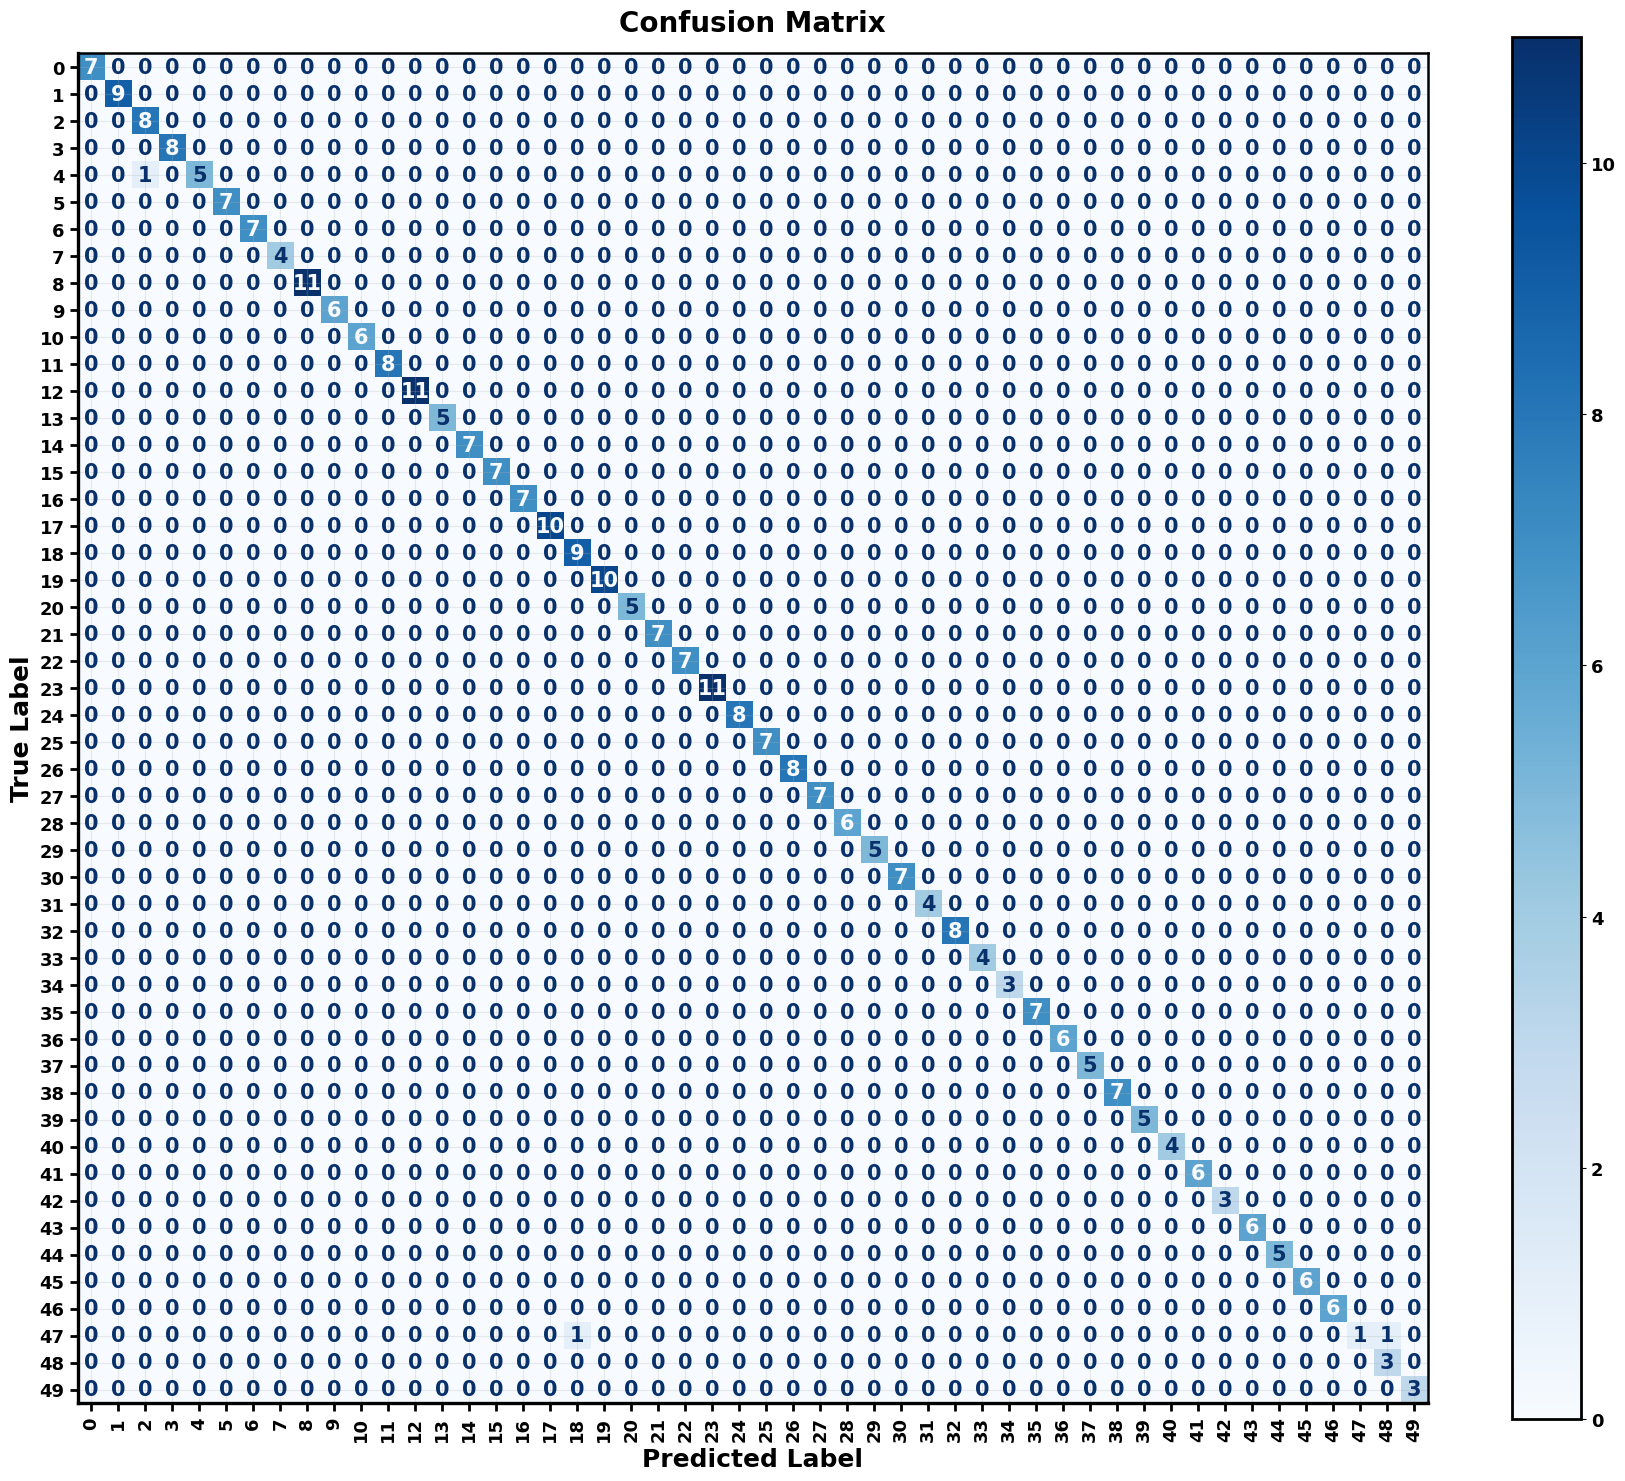

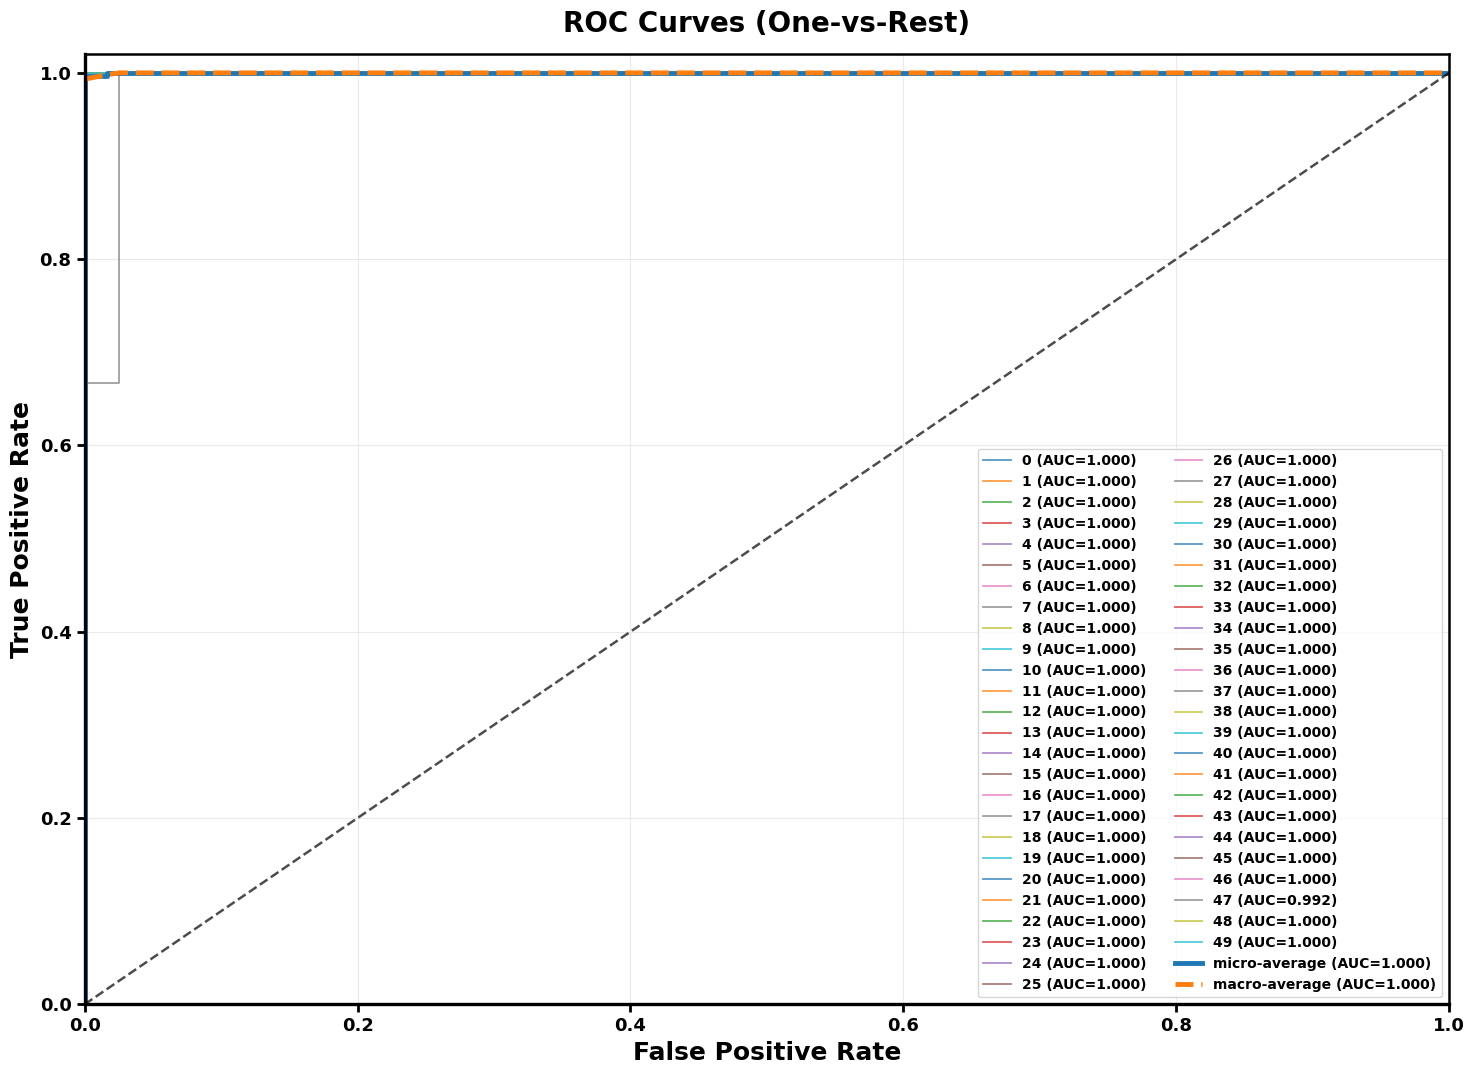

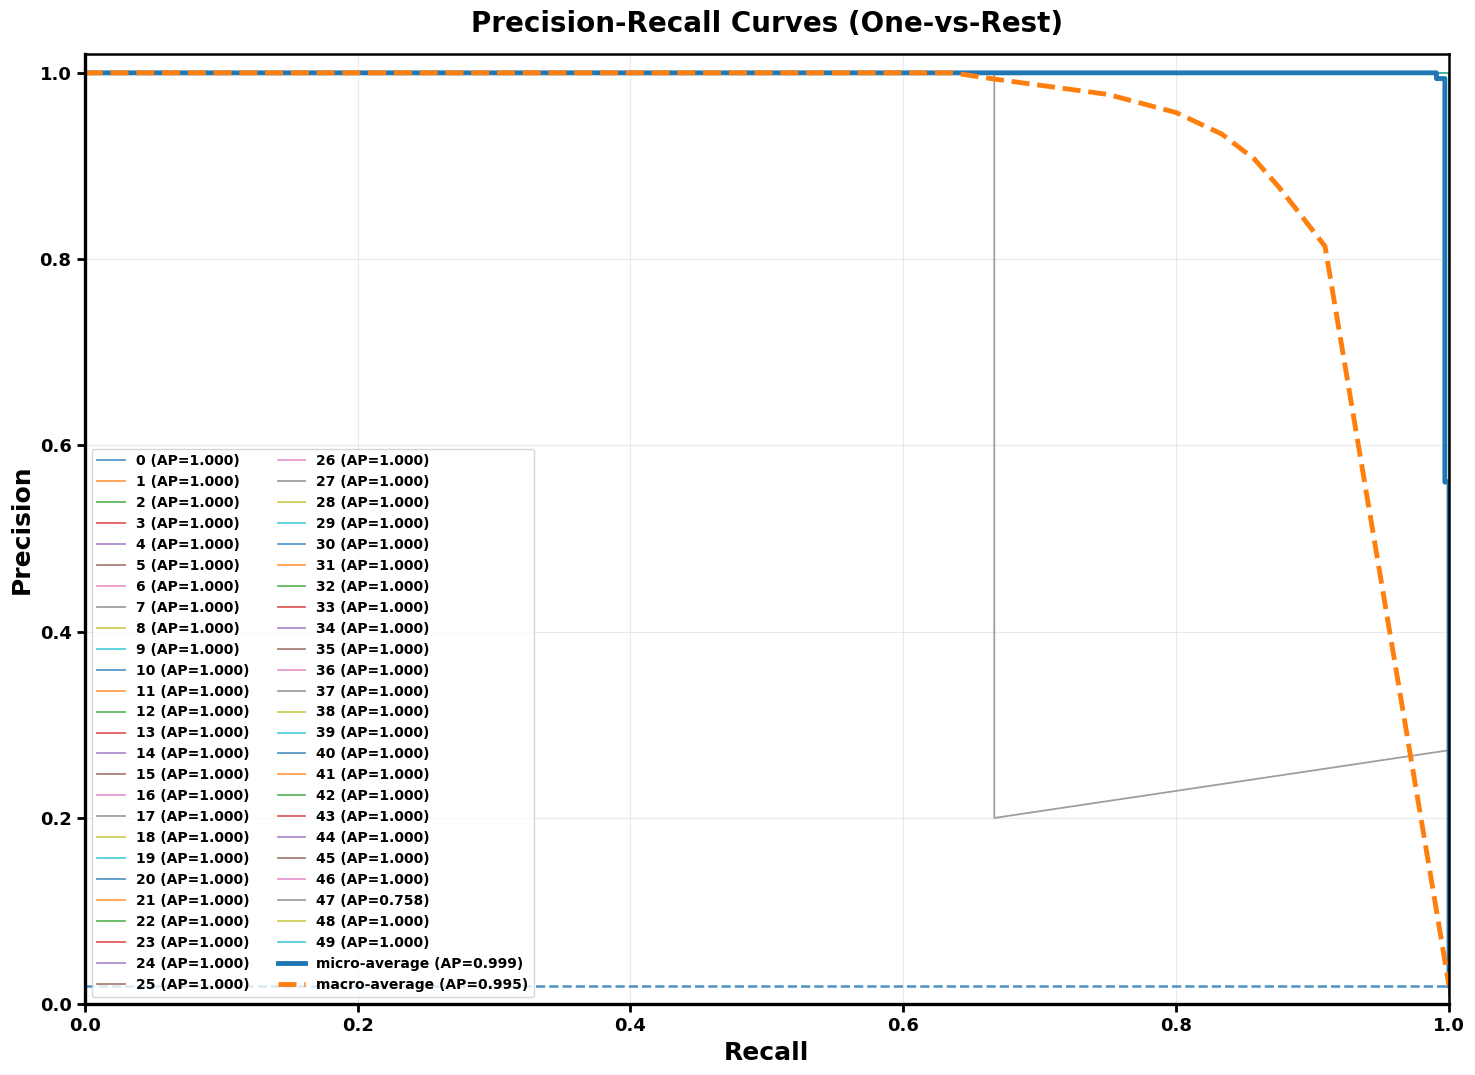

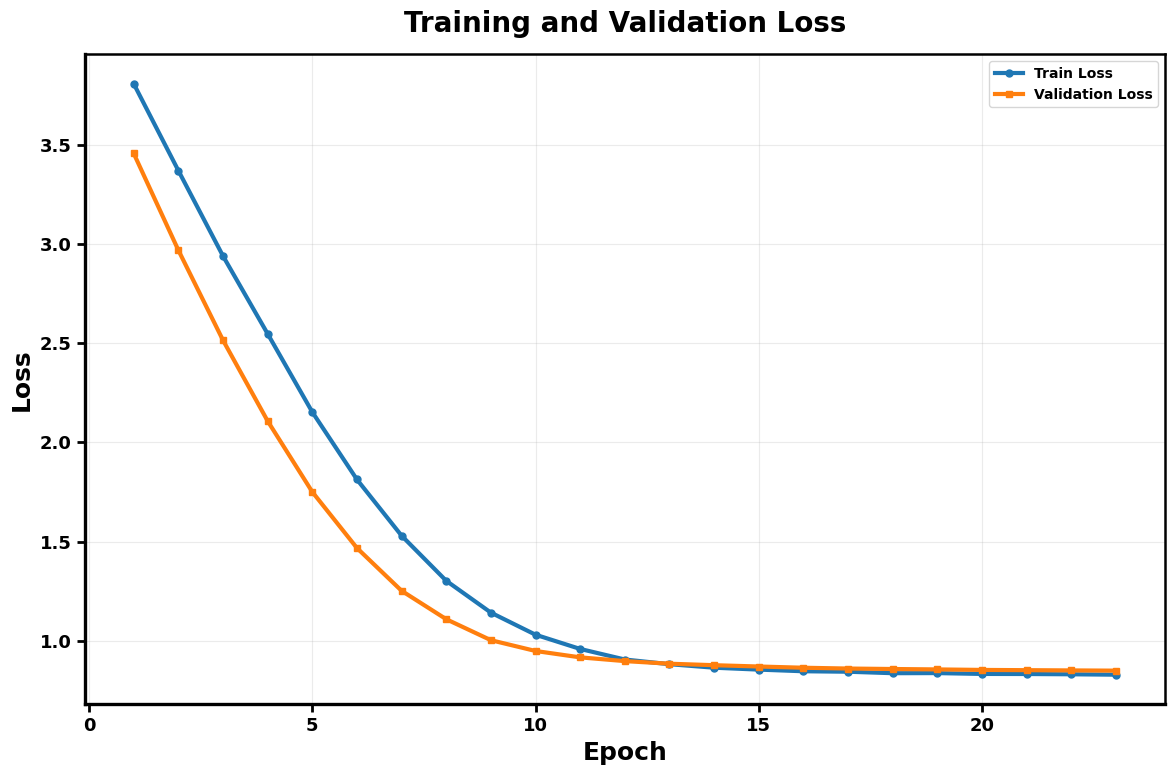

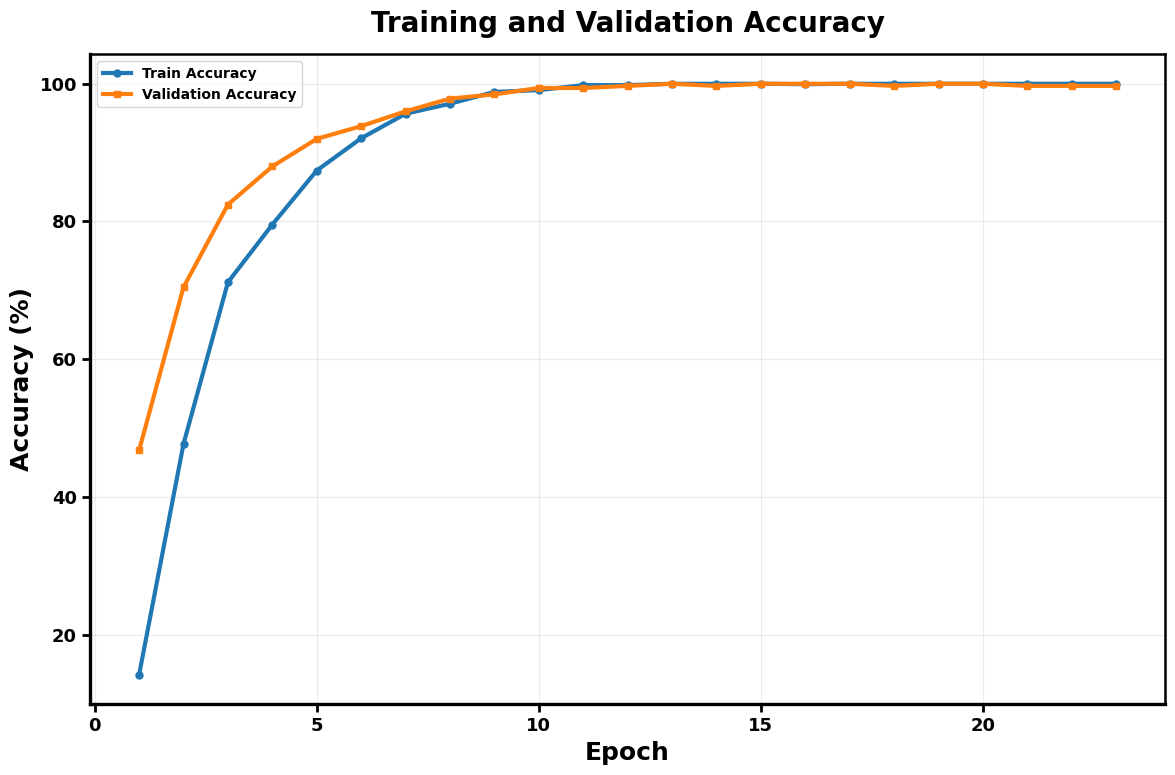

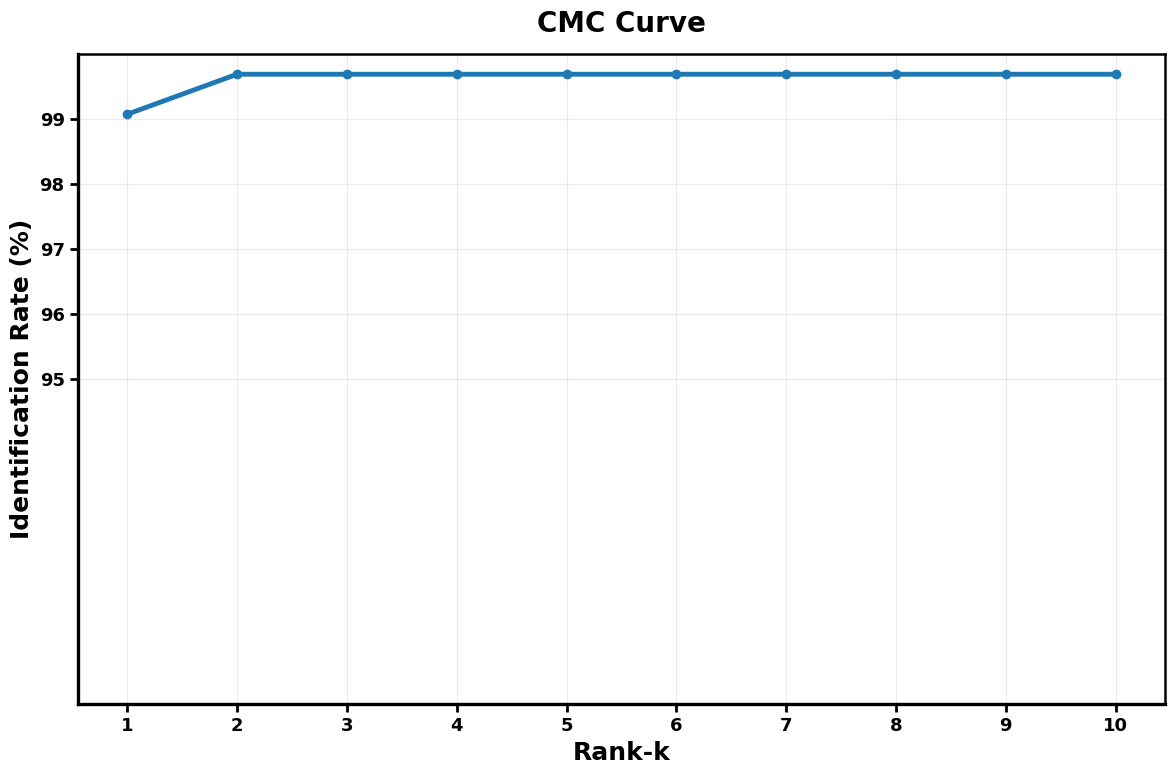


SAVED FILES
/kaggle/working/transformer_mlp_eval_plots/accuracy_curve.png
/kaggle/working/transformer_mlp_eval_plots/classification_report.txt
/kaggle/working/transformer_mlp_eval_plots/cmc_curve.png
/kaggle/working/transformer_mlp_eval_plots/cmc_curve_values.csv
/kaggle/working/transformer_mlp_eval_plots/confusion_matrix.csv
/kaggle/working/transformer_mlp_eval_plots/confusion_matrix.png
/kaggle/working/transformer_mlp_eval_plots/evaluation_summary.csv
/kaggle/working/transformer_mlp_eval_plots/loss_curve.png
/kaggle/working/transformer_mlp_eval_plots/precision_recall_ovr_micro_macro.png
/kaggle/working/transformer_mlp_eval_plots/roc_ovr_micro_macro.png
/kaggle/working/transformer_mlp_eval_plots/training_history_copy.csv

SUMMARY
          metric     value
0  test_accuracy  0.990769
1  micro_roc_auc  0.999950
2  macro_roc_auc  0.999917
3    micro_pr_ap  0.998612
4    macro_pr_ap  0.995152
5         rank_1  0.990769
6         rank_5  0.996923
7        rank_10  0.996923


In [15]:

# =========================
# STANDALONE EVALUATION CELL
# Transformer + MLP Head
# Run this as ONE Kaggle/Jupyter cell
# =========================

import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    classification_report,
    accuracy_score,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


# =========================
# CONFIG
# =========================
SEED = 42
BATCH_SIZE = 64
NUM_WORKERS = 2

INPUT_DIM = 1536
TOKEN_DIM = 512
D_MODEL = 256
NHEAD = 8
NUM_LAYERS = 2
FF_DIM = 512
DROPOUT = 0.2
MLP_HIDDEN = 256

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")
TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

MODEL_SAVE_PATH = Path("/kaggle/working/best_transformer_mlp_head.pth")
HISTORY_CSV_PATH = Path("/kaggle/working/transformer_mlp_history.csv")

OUT_DIR = Path("/kaggle/working/transformer_mlp_eval_plots")
OUT_DIR.mkdir(parents=True, exist_ok=True)


# =========================
# SEED
# =========================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# =========================
# PLOT STYLE
# =========================
plt.rcParams.update({
    "font.size": 15,
    "font.weight": "bold",
    "axes.labelsize": 18,
    "axes.labelweight": "bold",
    "axes.titlesize": 20,
    "axes.titleweight": "bold",
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 10,
    "axes.linewidth": 2.0,
})

def beautify_axes(ax):
    ax.spines["left"].set_linewidth(2.4)
    ax.spines["bottom"].set_linewidth(2.4)
    ax.spines["top"].set_linewidth(1.8)
    ax.spines["right"].set_linewidth(1.8)
    ax.tick_params(axis="both", width=2, length=6)
    ax.grid(alpha=0.25)


# =========================
# CHECK FILES
# =========================
assert TRAIN_FILE.exists(), f"Missing file: {TRAIN_FILE}"
assert VAL_FILE.exists(), f"Missing file: {VAL_FILE}"
assert TEST_FILE.exists(), f"Missing file: {TEST_FILE}"
assert MODEL_SAVE_PATH.exists(), f"Missing file: {MODEL_SAVE_PATH}"
assert HISTORY_CSV_PATH.exists(), f"Missing file: {HISTORY_CSV_PATH}"


# =========================
# LOAD DATA
# =========================
Dtr = np.load(TRAIN_FILE, allow_pickle=True)
Dva = np.load(VAL_FILE, allow_pickle=True)
Dte = np.load(TEST_FILE, allow_pickle=True)

X_train_raw = Dtr["X"].astype(np.float32)
y_train_raw = Dtr["y"]

X_val_raw = Dva["X"].astype(np.float32)
y_val_raw = Dva["y"]

X_test_raw = Dte["X"].astype(np.float32)
y_test_raw = Dte["y"]

assert X_train_raw.ndim == 2 and X_train_raw.shape[1] == INPUT_DIM
assert X_val_raw.ndim == 2 and X_val_raw.shape[1] == INPUT_DIM
assert X_test_raw.ndim == 2 and X_test_raw.shape[1] == INPUT_DIM

print("Train shape:", X_train_raw.shape)
print("Val shape  :", X_val_raw.shape)
print("Test shape :", X_test_raw.shape)


# =========================
# LABEL REMAP
# =========================
all_train_classes = sorted(np.unique(y_train_raw).tolist())
label_to_index = {label: idx for idx, label in enumerate(all_train_classes)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(y, label_to_index):
    return np.array([label_to_index[label] for label in y], dtype=np.int64)

y_train = remap_labels(y_train_raw, label_to_index)
y_val   = remap_labels(y_val_raw, label_to_index)
y_test  = remap_labels(y_test_raw, label_to_index)

num_classes = len(label_to_index)
class_names = [str(index_to_label[i]) for i in range(num_classes)]

print("num_classes:", num_classes)


# =========================
# STANDARDIZATION
# =========================
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val   = scaler.transform(X_val_raw).astype(np.float32)
X_test  = scaler.transform(X_test_raw).astype(np.float32)

print("Standardization complete.")


# =========================
# DATASET
# =========================
class MultiTokenFeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx].reshape(3, 512)
        y = self.y[idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.long)


test_ds = MultiTokenFeatureDataset(X_test, y_test)
test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


# =========================
# MODEL
# =========================
class TransformerMLPHead(nn.Module):
    def __init__(
        self,
        token_dim=512,
        d_model=256,
        nhead=8,
        num_layers=2,
        ff_dim=512,
        dropout=0.2,
        mlp_hidden=256,
        num_classes=10
    ):
        super().__init__()

        self.token_proj = nn.Sequential(
            nn.LayerNorm(token_dim),
            nn.Linear(token_dim, d_model)
        )

        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.pos_embed = nn.Parameter(torch.randn(1, 4, d_model) * 0.02)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.final_norm = nn.LayerNorm(d_model)

        self.mlp_head = nn.Sequential(
            nn.Linear(d_model, mlp_hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_hidden, num_classes)
        )

    def forward(self, x):
        B = x.size(0)
        x = self.token_proj(x)
        cls = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = x + self.pos_embed[:, :x.size(1), :]
        x = self.transformer(x)
        cls_out = self.final_norm(x[:, 0])
        logits = self.mlp_head(cls_out)
        return logits


model = TransformerMLPHead(
    token_dim=TOKEN_DIM,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT,
    mlp_hidden=MLP_HIDDEN,
    num_classes=num_classes
).to(DEVICE)

model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model.eval()

print("Loaded model from:", MODEL_SAVE_PATH)


# =========================
# GET TEST OUTPUTS
# =========================
@torch.no_grad()
def get_outputs(model, loader):
    model.eval()
    all_logits = []
    all_labels = []

    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        all_logits.append(logits.cpu())
        all_labels.append(yb.cpu())

    all_logits = torch.cat(all_logits, dim=0).numpy()
    all_labels = torch.cat(all_labels, dim=0).numpy()
    return all_logits, all_labels

test_logits, y_true = get_outputs(model, test_loader)

def softmax_np(x):
    x = x - np.max(x, axis=1, keepdims=True)
    e = np.exp(x)
    return e / (np.sum(e, axis=1, keepdims=True) + 1e-12)

probs = softmax_np(test_logits)
y_pred = np.argmax(probs, axis=1)

test_acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Y_onehot = np.zeros((len(y_true), num_classes), dtype=np.int32)
Y_onehot[np.arange(len(y_true)), y_true] = 1


# =========================
# CLASSIFICATION REPORT
# =========================
report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

with open(OUT_DIR / "classification_report.txt", "w") as f:
    f.write(report_text)

print("\nClassification Report:\n")
print(report_text)


# =========================
# CONFUSION MATRIX

# =========================
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
cm_df.to_csv(OUT_DIR / "confusion_matrix.csv", index=True)

fig, ax = plt.subplots(figsize=(18, 15))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=90, colorbar=True, values_format="d", cmap="Blues")
ax.set_title("Confusion Matrix", pad=16, fontweight="bold")
ax.set_xlabel("Predicted Label", fontweight="bold")
ax.set_ylabel("True Label", fontweight="bold")
beautify_axes(ax)
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=1200, bbox_inches="tight")
plt.show()
plt.close()


# =========================
# ROC CURVES
# =========================
fpr = {}
tpr = {}
roc_auc = {}

valid_classes = []
for i in range(num_classes):
    if Y_onehot[:, i].sum() == 0:
        continue
    fpr[i], tpr[i], _ = roc_curve(Y_onehot[:, i], probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    valid_classes.append(i)

fpr["micro"], tpr["micro"], _ = roc_curve(Y_onehot.ravel(), probs.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

all_fpr = np.unique(np.concatenate([fpr[i] for i in valid_classes]))
mean_tpr = np.zeros_like(all_fpr)
for i in valid_classes:
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= max(1, len(valid_classes))

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

fig, ax = plt.subplots(figsize=(15, 11))

for i in valid_classes:
    ax.plot(
        fpr[i],
        tpr[i],
        lw=1.3,
        alpha=0.75,
        label=f"{class_names[i]} (AUC={roc_auc[i]:.3f})"
    )

ax.plot(
    fpr["micro"],
    tpr["micro"],
    lw=3.5,
    label=f"micro-average (AUC={roc_auc['micro']:.3f})"
)

ax.plot(
    fpr["macro"],
    tpr["macro"],
    lw=3.5,
    linestyle="--",
    label=f"macro-average (AUC={roc_auc['macro']:.3f})"
)

ax.plot([0, 1], [0, 1], "k--", lw=1.8, alpha=0.7)
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.set_xlabel("False Positive Rate", fontweight="bold")
ax.set_ylabel("True Positive Rate", fontweight="bold")
ax.set_title("ROC Curves (One-vs-Rest)", pad=16, fontweight="bold")
ax.legend(loc="lower right", fontsize=10, ncol=2, frameon=True)
beautify_axes(ax)
plt.tight_layout()
plt.savefig(OUT_DIR / "roc_ovr_micro_macro.png", dpi=1200, bbox_inches="tight")
plt.show()
plt.close()


# =========================
# PRECISION-RECALL CURVES
# =========================
precision = {}
recall = {}
ap_score = {}

valid_classes_pr = []
for i in range(num_classes):
    if Y_onehot[:, i].sum() == 0:
        continue
    precision[i], recall[i], _ = precision_recall_curve(Y_onehot[:, i], probs[:, i])
    ap_score[i] = average_precision_score(Y_onehot[:, i], probs[:, i])
    valid_classes_pr.append(i)

precision["micro"], recall["micro"], _ = precision_recall_curve(Y_onehot.ravel(), probs.ravel())
ap_score["micro"] = average_precision_score(Y_onehot, probs, average="micro")
ap_score["macro"] = float(np.mean([ap_score[i] for i in valid_classes_pr])) if len(valid_classes_pr) else float("nan")

all_recall = np.unique(np.concatenate([recall[i] for i in valid_classes_pr]))
mean_precision = np.zeros_like(all_recall)

for i in valid_classes_pr:
    order = np.argsort(recall[i])
    r_sorted = recall[i][order]
    p_sorted = precision[i][order]
    mean_precision += np.interp(all_recall, r_sorted, p_sorted)

mean_precision /= max(1, len(valid_classes_pr))
recall["macro"] = all_recall
precision["macro"] = mean_precision

positive_rate = Y_onehot.mean()

fig, ax = plt.subplots(figsize=(15, 11))

for i in valid_classes_pr:
    ax.plot(
        recall[i],
        precision[i],
        lw=1.3,
        alpha=0.75,
        label=f"{class_names[i]} (AP={ap_score[i]:.3f})"
    )

ax.plot(
    recall["micro"],
    precision["micro"],
    lw=3.5,
    label=f"micro-average (AP={ap_score['micro']:.3f})"
)

ax.plot(
    recall["macro"],
    precision["macro"],
    lw=3.5,
    linestyle="--",
    label=f"macro-average (AP={ap_score['macro']:.3f})"
)

ax.hlines(
    y=positive_rate,
    xmin=0,
    xmax=1,
    linestyles="--",
    lw=1.8,
    alpha=0.8
)

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.set_xlabel("Recall", fontweight="bold")
ax.set_ylabel("Precision", fontweight="bold")
ax.set_title("Precision-Recall Curves (One-vs-Rest)", pad=16, fontweight="bold")
ax.legend(loc="lower left", fontsize=10, ncol=2, frameon=True)
beautify_axes(ax)
plt.tight_layout()
plt.savefig(OUT_DIR / "precision_recall_ovr_micro_macro.png", dpi=900, bbox_inches="tight")
plt.show()
plt.close()


# =========================
# LOSS CURVE
# =========================
history_df = pd.read_csv(HISTORY_CSV_PATH)
history_df.to_csv(OUT_DIR / "training_history_copy.csv", index=False)

epochs = np.arange(1, len(history_df) + 1)

fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(epochs, history_df["train_loss"], linewidth=3, marker="o", markersize=5, label="Train Loss")
ax.plot(epochs, history_df["val_loss"], linewidth=3, marker="s", markersize=5, label="Validation Loss")
ax.set_xlabel("Epoch", fontweight="bold")
ax.set_ylabel("Loss", fontweight="bold")
ax.set_title("Training and Validation Loss", pad=16, fontweight="bold")
ax.legend(frameon=True)
beautify_axes(ax)
plt.tight_layout()
plt.savefig(OUT_DIR / "loss_curve.png", dpi=1200, bbox_inches="tight")
plt.show()
plt.close()


# =========================
# ACCURACY CURVE
# =========================
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(epochs, history_df["train_acc"] * 100, linewidth=3, marker="o", markersize=5, label="Train Accuracy")
ax.plot(epochs, history_df["val_acc"] * 100, linewidth=3, marker="s", markersize=5, label="Validation Accuracy")
ax.set_xlabel("Epoch", fontweight="bold")
ax.set_ylabel("Accuracy (%)", fontweight="bold")
ax.set_title("Training and Validation Accuracy", pad=16, fontweight="bold")
ax.legend(frameon=True)
beautify_axes(ax)
plt.tight_layout()
plt.savefig(OUT_DIR / "accuracy_curve.png", dpi=1200, bbox_inches="tight")
plt.show()
plt.close()


# =========================
# CMC CURVE
# =========================
sorted_indices = np.argsort(-probs, axis=1)

ranks = []
for i in range(len(y_true)):
    rank_pos = np.where(sorted_indices[i] == y_true[i])[0][0] + 1
    ranks.append(rank_pos)

ranks = np.array(ranks)

max_rank = min(num_classes, 10)
cmc = []
for k in range(1, max_rank + 1):
    cmc.append(np.mean(ranks <= k))

cmc_df = pd.DataFrame({
    "rank": np.arange(1, max_rank + 1),
    "cmc_accuracy": cmc
})
cmc_df.to_csv(OUT_DIR / "cmc_curve_values.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(np.arange(1, max_rank + 1), np.array(cmc) * 100, linewidth=3.5, marker="o", markersize=6)
ax.set_xlabel("Rank-k", fontweight="bold")
ax.set_ylabel("Identification Rate (%)", fontweight="bold")
ax.set_title("CMC Curve", pad=16, fontweight="bold")
ax.set_xticks(np.arange(1, max_rank + 1))
ax.set_ylim(90, 100)
ax.set_yticks(np.arange(95, 100))   # 90,92,94...100
beautify_axes(ax)
plt.tight_layout()
plt.savefig(OUT_DIR / "cmc_curve.png", dpi=1200, bbox_inches="tight")
plt.show()
plt.close()


# =========================
# SAVE SUMMARY
# =========================
summary_df = pd.DataFrame([
    {"metric": "test_accuracy", "value": test_acc},
    {"metric": "micro_roc_auc", "value": roc_auc["micro"]},
    {"metric": "macro_roc_auc", "value": roc_auc["macro"]},
    {"metric": "micro_pr_ap", "value": ap_score["micro"]},
    {"metric": "macro_pr_ap", "value": ap_score["macro"]},
    {"metric": "rank_1", "value": cmc[0] if len(cmc) >= 1 else np.nan},
    {"metric": "rank_5", "value": cmc[4] if len(cmc) >= 5 else np.nan},
    {"metric": "rank_10", "value": cmc[9] if len(cmc) >= 10 else np.nan},
])

summary_df.to_csv(OUT_DIR / "evaluation_summary.csv", index=False)

print("\n=========================")
print("SAVED FILES")
print("=========================")
for p in sorted(OUT_DIR.glob("*")):
    print(p)

print("\n=========================")
print("SUMMARY")
print("=========================")
print(summary_df)

In [16]:
# ============================================================
# XAI for Transformer + MLP Head using 1536 fused features:
#   1) Global important features via Permutation Importance (Top-30)
#   2) Modality importance (skel/sil/heat blocks of 512)
#   3) LIME explanations on 1536 fused input (wraps Transformer + MLP Head)
#
# Expected input files:
#   /kaggle/working/features/closed_set_splits/
#       train_closedset_70_15_15.npz
#       val_closedset_70_15_15.npz
#       test_closedset_70_15_15.npz
#
# Each .npz must contain keys:
#   X, y, person_ids
#
# Outputs -> OUT_DIR
# ============================================================

from pathlib import Path
import os
import sys
import copy
import random
import subprocess
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# ---------------------------
# Repro / Device
# ---------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)


# ---------------------------
# Paths
# ---------------------------
SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")
TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

MODEL_SAVE_PATH = Path("/kaggle/working/best_transformer_mlp_head.pth")
OUT_DIR = Path("/kaggle/working/plots_transformer_mlp_xai_1536")
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert TRAIN_FILE.exists(), f"Missing file: {TRAIN_FILE}"
assert VAL_FILE.exists(),   f"Missing file: {VAL_FILE}"
assert TEST_FILE.exists(),  f"Missing file: {TEST_FILE}"
assert MODEL_SAVE_PATH.exists(), f"Missing trained model: {MODEL_SAVE_PATH}"

print("Train file:", TRAIN_FILE)
print("Val file  :", VAL_FILE)
print("Test file :", TEST_FILE)
print("Model file:", MODEL_SAVE_PATH)
print("Output dir:", OUT_DIR)


# ---------------------------
# Hyperparams (same model settings)
# ---------------------------
BATCH_SIZE = 128
NUM_WORKERS = 2

INPUT_DIM = 1536
TOKEN_DIM = 512
D_MODEL = 256
NHEAD = 8
NUM_LAYERS = 2
FF_DIM = 512
DROPOUT = 0.2
MLP_HIDDEN = 256

LABEL_SMOOTHING = 0.1
USE_CLASS_WEIGHTS = True

# Permutation importance
N_REPEATS = 5
TOPK = 30

# LIME
N_LIME_EXAMPLES = 5


# ---------------------------
# Load data
# ---------------------------
Dtr = np.load(TRAIN_FILE, allow_pickle=True)
Dva = np.load(VAL_FILE, allow_pickle=True)
Dte = np.load(TEST_FILE, allow_pickle=True)

print("\nTrain keys:", Dtr.files)
print("Val keys  :", Dva.files)
print("Test keys :", Dte.files)

X_train_raw = Dtr["X"].astype(np.float32)
y_train_raw = Dtr["y"]
p_train     = Dtr["person_ids"]

X_val_raw = Dva["X"].astype(np.float32)
y_val_raw = Dva["y"]
p_val     = Dva["person_ids"]

X_test_raw = Dte["X"].astype(np.float32)
y_test_raw = Dte["y"]
p_test     = Dte["person_ids"]


# ---------------------------
# Shape check
# ---------------------------
print("\n=========================")
print("SHAPE CHECK")
print("=========================")
print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)
print("X_val  :", X_val_raw.shape)
print("y_val  :", y_val_raw.shape)
print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

assert X_train_raw.ndim == 2 and X_train_raw.shape[1] == INPUT_DIM, f"Expected (N, {INPUT_DIM})"
assert X_val_raw.ndim   == 2 and X_val_raw.shape[1]   == INPUT_DIM, f"Expected (N, {INPUT_DIM})"
assert X_test_raw.ndim  == 2 and X_test_raw.shape[1]  == INPUT_DIM, f"Expected (N, {INPUT_DIM})"


# ---------------------------
# Label remap (same as training)
# ---------------------------
print("\n=========================")
print("RAW LABEL CHECK")
print("=========================")
print("Train unique labels:", np.unique(y_train_raw))
print("Val unique labels  :", np.unique(y_val_raw))
print("Test unique labels :", np.unique(y_test_raw))

train_set = set(np.unique(y_train_raw))
val_set   = set(np.unique(y_val_raw))
test_set  = set(np.unique(y_test_raw))

if not (val_set.issubset(train_set) and test_set.issubset(train_set)):
    raise ValueError("Val/Test contain classes not present in train.")

all_train_classes = sorted(np.unique(y_train_raw).tolist())
label_to_index = {label: idx for idx, label in enumerate(all_train_classes)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(y, label_to_index):
    return np.array([label_to_index[label] for label in y], dtype=np.int64)

y_train = remap_labels(y_train_raw, label_to_index)
y_val   = remap_labels(y_val_raw, label_to_index)
y_test  = remap_labels(y_test_raw, label_to_index)

num_classes = len(label_to_index)

print("\nnum_classes:", num_classes)
print("Chance accuracy ~", round(100 / num_classes, 2), "%")


# ---------------------------
# Standardization (same as training)
# ---------------------------
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val   = scaler.transform(X_val_raw).astype(np.float32)
X_test  = scaler.transform(X_test_raw).astype(np.float32)

print("\nFeature standardization done.")


# ---------------------------
# Dataset / loaders
# ---------------------------
class MultiTokenFeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx].reshape(3, 512)   # (3,512)
        y = self.y[idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

train_ds = MultiTokenFeatureDataset(X_train, y_train)
val_ds   = MultiTokenFeatureDataset(X_val, y_val)
test_ds  = MultiTokenFeatureDataset(X_test, y_test)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

print("\nDataloaders ready.")
print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))


# ---------------------------
# Class weights (same as training)
# ---------------------------
if USE_CLASS_WEIGHTS:
    class_counts = np.bincount(y_train, minlength=num_classes)
    class_weights = class_counts.sum() / (num_classes * np.maximum(class_counts, 1))
    class_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

    print("\nClass counts:", class_counts)
    print("Class weights:", class_weights.detach().cpu().numpy())
else:
    class_weights = None


# ---------------------------
# Model: same Transformer + MLP Head
# ---------------------------
class TransformerMLPHead(nn.Module):
    def __init__(
        self,
        token_dim=512,
        d_model=256,
        nhead=8,
        num_layers=2,
        ff_dim=512,
        dropout=0.2,
        mlp_hidden=256,
        num_classes=10
    ):
        super().__init__()

        self.token_proj = nn.Sequential(
            nn.LayerNorm(token_dim),
            nn.Linear(token_dim, d_model)
        )

        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.pos_embed = nn.Parameter(torch.randn(1, 4, d_model) * 0.02)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.final_norm = nn.LayerNorm(d_model)

        self.mlp_head = nn.Sequential(
            nn.Linear(d_model, mlp_hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_hidden, num_classes)
        )

    def forward(self, x):
        # x: (B, 3, 512)
        B = x.size(0)

        x = self.token_proj(x)                 # (B, 3, d_model)

        cls = self.cls_token.expand(B, -1, -1) # (B, 1, d_model)
        x = torch.cat([cls, x], dim=1)         # (B, 4, d_model)

        x = x + self.pos_embed[:, :x.size(1), :]
        x = self.transformer(x)                # (B, 4, d_model)

        cls_out = x[:, 0]
        cls_out = self.final_norm(cls_out)

        logits = self.mlp_head(cls_out)
        return logits


model = TransformerMLPHead(
    token_dim=TOKEN_DIM,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT,
    mlp_hidden=MLP_HIDDEN,
    num_classes=num_classes
).to(DEVICE)

print("\nModel created.")
print(model)


# ---------------------------
# Loss
# ---------------------------
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=LABEL_SMOOTHING
)


# ---------------------------
# Load best trained model
# ---------------------------
model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model.eval()

print("\nLoaded trained model from:", MODEL_SAVE_PATH)


# ---------------------------
# Eval helper
# ---------------------------
def run_one_epoch(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            logits = model(xb)
            loss = criterion(logits, yb)

            total_loss += loss.item() * xb.size(0)

            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.detach().cpu().numpy().tolist())
            all_targets.extend(yb.detach().cpu().numpy().tolist())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds)

    return avg_loss, acc, np.array(all_targets), np.array(all_preds)


# ---------------------------
# Final evaluation
# ---------------------------
val_loss, val_acc, yv_true, yv_pred = run_one_epoch(model, val_loader, criterion)
test_loss, test_acc, y_true, y_pred = run_one_epoch(model, test_loader, criterion)

print("\n=========================")
print("VALIDATION / TEST RESULT")
print("=========================")
print(f"Val  Loss: {val_loss:.4f}")
print(f"Val  Acc : {val_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Acc : {test_acc * 100:.2f}%")


# ---------------------------
# Classification report
# ---------------------------
target_names = [str(index_to_label[i]) for i in range(num_classes)]

report = classification_report(
    y_true,
    y_pred,
    target_names=target_names,
    digits=4,
    zero_division=0
)

print("\n=========================")
print("CLASSIFICATION REPORT")
print("=========================")
print(report)


# ---------------------------
# Confusion matrix
# ---------------------------
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(
    cm,
    index=[f"true_{index_to_label[i]}" for i in range(num_classes)],
    columns=[f"pred_{index_to_label[i]}" for i in range(num_classes)]
)

print("\nConfusion Matrix:")
print(cm_df)


# ---------------------------
# Helper: predict_proba from raw 1536
# ---------------------------
def predict_proba_1536(X1536_raw: np.ndarray) -> np.ndarray:
    """
    X1536_raw: (N,1536) unscaled/raw
    Returns: (N,C) probabilities from Transformer + MLP Head
    """
    model.eval()

    Xs = scaler.transform(X1536_raw).astype(np.float32)
    Xt = Xs.reshape(-1, 3, 512).astype(np.float32)

    probs = []
    with torch.no_grad():
        for i in range(0, len(Xt), 256):
            xb = torch.from_numpy(Xt[i:i+256]).to(DEVICE)
            logits = model(xb)
            p = torch.softmax(logits, dim=1).cpu().numpy()
            probs.append(p)

    return np.concatenate(probs, axis=0)

def predict_label_1536(X1536_raw: np.ndarray) -> np.ndarray:
    return np.argmax(predict_proba_1536(X1536_raw), axis=1)


# ---------------------------
# SKLEARN-style wrapper
# ---------------------------
class TorchTransformerMLPSkWrapper:
    def fit(self, X, y):
        return self

    def predict(self, X):
        return predict_label_1536(X)

    def predict_proba(self, X):
        return predict_proba_1536(X)

    def score(self, X, y):
        yp = self.predict(X)
        return accuracy_score(y, yp)

sk_est = TorchTransformerMLPSkWrapper()


# ---------------------------
# 1) Permutation Importance
# ---------------------------
print("\nComputing permutation importance on VAL (1536 dims) ...")
res = permutation_importance(
    sk_est,
    X_val_raw,     # raw/unscaled, wrapper handles scaling
    y_val,
    n_repeats=N_REPEATS,
    random_state=0,
    n_jobs=-1,
)

imp_mean = res.importances_mean
imp_std  = res.importances_std

idx_top = np.argsort(imp_mean)[::-1][:TOPK]
feat_names = np.array([f"f_{i}" for i in range(1536)])

plt.figure(figsize=(8, 6))
plt.barh(range(TOPK), imp_mean[idx_top][::-1], color="royalblue")
plt.yticks(range(TOPK), feat_names[idx_top][::-1])
plt.xlabel("Mean accuracy decrease")
plt.title(f"Top-{TOPK} Important Features")
plt.tight_layout()
perm_path = OUT_DIR / "transformer_mlp_perm_importance_top30_1536.png"
plt.savefig(perm_path, dpi=1200, bbox_inches="tight")
plt.close()
print("Saved:", perm_path)


# ---------------------------
# 2) Modality Importance
# ---------------------------
d = 512
skel_imp = float(np.mean(imp_mean[0:d]))
sil_imp  = float(np.mean(imp_mean[d:2*d]))
heat_imp = float(np.mean(imp_mean[2*d:3*d]))

mod_names = ["Skeleton", "Silhouette", "Heatmap"]
mod_vals  = [skel_imp, sil_imp, heat_imp]

plt.figure(figsize=(6, 5))
plt.bar(mod_names, mod_vals, color=["dodgerblue", "seagreen", "crimson"])
plt.title("Modality Importance")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
mod_path = OUT_DIR / "transformer_mlp_modality_importance_1536.png"
plt.savefig(mod_path, dpi=1200, bbox_inches="tight")
plt.close()
print("Saved:", mod_path)


# ---------------------------
# 3) LIME explanations
# ---------------------------
def ensure_lime():
    try:
        import lime  # noqa: F401
        return
    except Exception:
        print("\nLIME not found. Installing 'lime' ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime"])

ensure_lime()
from lime.lime_tabular import LimeTabularExplainer

class_names = [str(index_to_label[i]) for i in range(num_classes)]
feature_names = [f"f_{i}" for i in range(1536)]

explainer = LimeTabularExplainer(
    training_data=X_train_raw,   # raw training features
    feature_names=feature_names,
    class_names=class_names,
    discretize_continuous=True,
    mode="classification",
)

rng = np.random.RandomState(123)
idxs = rng.choice(len(X_test_raw), size=min(N_LIME_EXAMPLES, len(X_test_raw)), replace=False)

print("\nGenerating LIME explanations (HTML + bar PNG) ...")

for n, idx in enumerate(idxs, start=1):
    x = X_test_raw[idx]
    true_label = int(y_test[idx])
    pred = int(predict_label_1536(x.reshape(1, -1))[0])

    exp = explainer.explain_instance(
        data_row=x,
        predict_fn=predict_proba_1536,
        num_features=15,
        top_labels=1,
    )

    html_path = OUT_DIR / f"lime_transformer_mlp_1536_ex{n}.html"
    exp.save_to_file(str(html_path))

    weights = exp.as_list(label=pred)
    names = [w[0] for w in weights][::-1]
    vals  = [w[1] for w in weights][::-1]

    plt.figure(figsize=(8, 5))
    plt.barh(range(len(vals)), vals)
    plt.yticks(range(len(vals)), names)
    plt.title(
        f"LIME (Transformer + MLP Head, 1536) Example {n} | "
        f"True={index_to_label[true_label]} Pred={index_to_label[pred]}"
    )
    plt.tight_layout()
    png_path = OUT_DIR / f"lime_transformer_mlp_1536_ex{n}.png"
    plt.savefig(png_path, dpi=250, bbox_inches="tight")
    plt.close()

    print(f"Example {n}: saved {html_path.name} and {png_path.name}")


# ---------------------------
# Save report
# ---------------------------
report_txt_path = OUT_DIR / "transformer_mlp_xai_report.txt"
with open(report_txt_path, "w") as f:
    f.write(f"Val acc: {val_acc * 100:.2f}%\n")
    f.write(f"Test acc: {test_acc * 100:.2f}%\n\n")
    f.write(report)
    f.write("\n\nConfusion Matrix:\n")
    f.write(cm_df.to_string())

print("\nSaved report to:", report_txt_path)

print("\n✅ DONE.")
print("All outputs saved in:", OUT_DIR)


Using device: cuda
Train file: /kaggle/working/features/closed_set_splits/train_closedset_70_15_15.npz
Val file  : /kaggle/working/features/closed_set_splits/val_closedset_70_15_15.npz
Test file : /kaggle/working/features/closed_set_splits/test_closedset_70_15_15.npz
Model file: /kaggle/working/best_transformer_mlp_head.pth
Output dir: /kaggle/working/plots_transformer_mlp_xai_1536

Train keys: ['X', 'y', 'person_ids']
Val keys  : ['X', 'y', 'person_ids']
Test keys : ['X', 'y', 'person_ids']

SHAPE CHECK
X_train: (1516, 1536)
y_train: (1516,)
X_val  : (325, 1536)
y_val  : (325,)
X_test : (325, 1536)
y_test : (325,)

RAW LABEL CHECK
Train unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Val unique labels  : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Test uniqu

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(



VALIDATION / TEST RESULT
Val  Loss: 0.8825
Val  Acc : 100.00%
Test Loss: 0.9016
Test Acc : 99.08%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000         7
           1     1.0000    1.0000    1.0000         9
           2     0.8889    1.0000    0.9412         8
           3     1.0000    1.0000    1.0000         8
           4     1.0000    0.8333    0.9091         6
           5     1.0000    1.0000    1.0000         7
           6     1.0000    1.0000    1.0000         7
           7     1.0000    1.0000    1.0000         4
           8     1.0000    1.0000    1.0000        11
           9     1.0000    1.0000    1.0000         6
          10     1.0000    1.0000    1.0000         6
          11     1.0000    1.0000    1.0000         8
          12     1.0000    1.0000    1.0000        11
          13     1.0000    1.0000    1.0000         5
          14     1.0000    1.0000    1.0000         7
          15 

X_test: (325, 1536)
y_test: (325,)
Using samples: 325


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


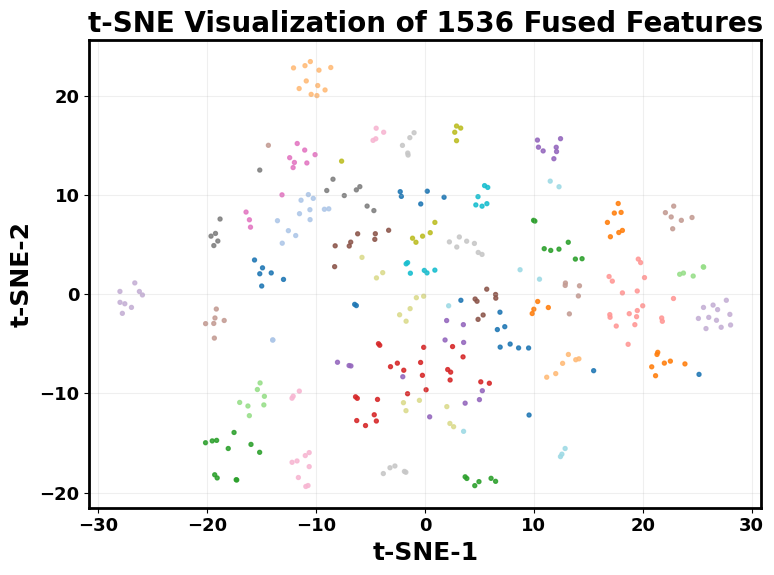

Saved: /kaggle/working/plots_transformer_mlp_xai_1536/tsne_1536_test.png


In [17]:
# ============================================================
# t-SNE visualization for 1536 fused features
# Compatible with your Transformer + MLP Head pipeline
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

# =========================
# PATHS (same as training)
# =========================
SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")

TRAIN_FILE = SPLIT_DIR / "train_closedset_70_15_15.npz"
VAL_FILE   = SPLIT_DIR / "val_closedset_70_15_15.npz"
TEST_FILE  = SPLIT_DIR / "test_closedset_70_15_15.npz"

OUT_DIR = Path("/kaggle/working/plots_transformer_mlp_xai_1536")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# =========================
# LOAD DATA
# =========================
Dte = np.load(TEST_FILE, allow_pickle=True)

X_test = Dte["X"].astype(np.float32)   # (N,1536)
y_test = Dte["y"]

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# =========================
# SELECT DATA FOR VISUALIZATION
# =========================
X_vis = X_test
y_vis = y_test

# Downsample if dataset too large
MAX_POINTS = 3000
rng = np.random.RandomState(42)

if len(X_vis) > MAX_POINTS:
    idx = rng.choice(len(X_vis), size=MAX_POINTS, replace=False)
    X_vis = X_vis[idx]
    y_vis = y_vis[idx]

print("Using samples:", len(X_vis))

# =========================
# SCALE FEATURES
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_vis)

# =========================
# RUN t-SNE
# =========================
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42,
    n_iter=1500
)

X_2d = tsne.fit_transform(X_scaled)

# =========================
# PLOT
# =========================
plt.figure(figsize=(8,6))

scatter = plt.scatter(
    X_2d[:,0],
    X_2d[:,1],
    c=y_vis,
    cmap="tab20",
    s=8,
    alpha=0.85
)

plt.title("t-SNE Visualization of 1536 Fused Features")
plt.xlabel("t-SNE-1")
plt.ylabel("t-SNE-2")

plt.grid(alpha=0.2)

plt.tight_layout()

# =========================
# SAVE
# =========================
out_path = OUT_DIR / "tsne_1536_test.png"

plt.savefig(out_path, dpi=900, bbox_inches="tight")
plt.show()

print("Saved:", out_path)

2026-03-12 21:23:49.634787: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773350629.855433      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773350629.909544      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773350630.377922      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773350630.377962      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773350630.377965      23 computation_placer.cc:177] computation placer alr

X_test: (325, 1536)
y_test: (325,)
Using samples: 325


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


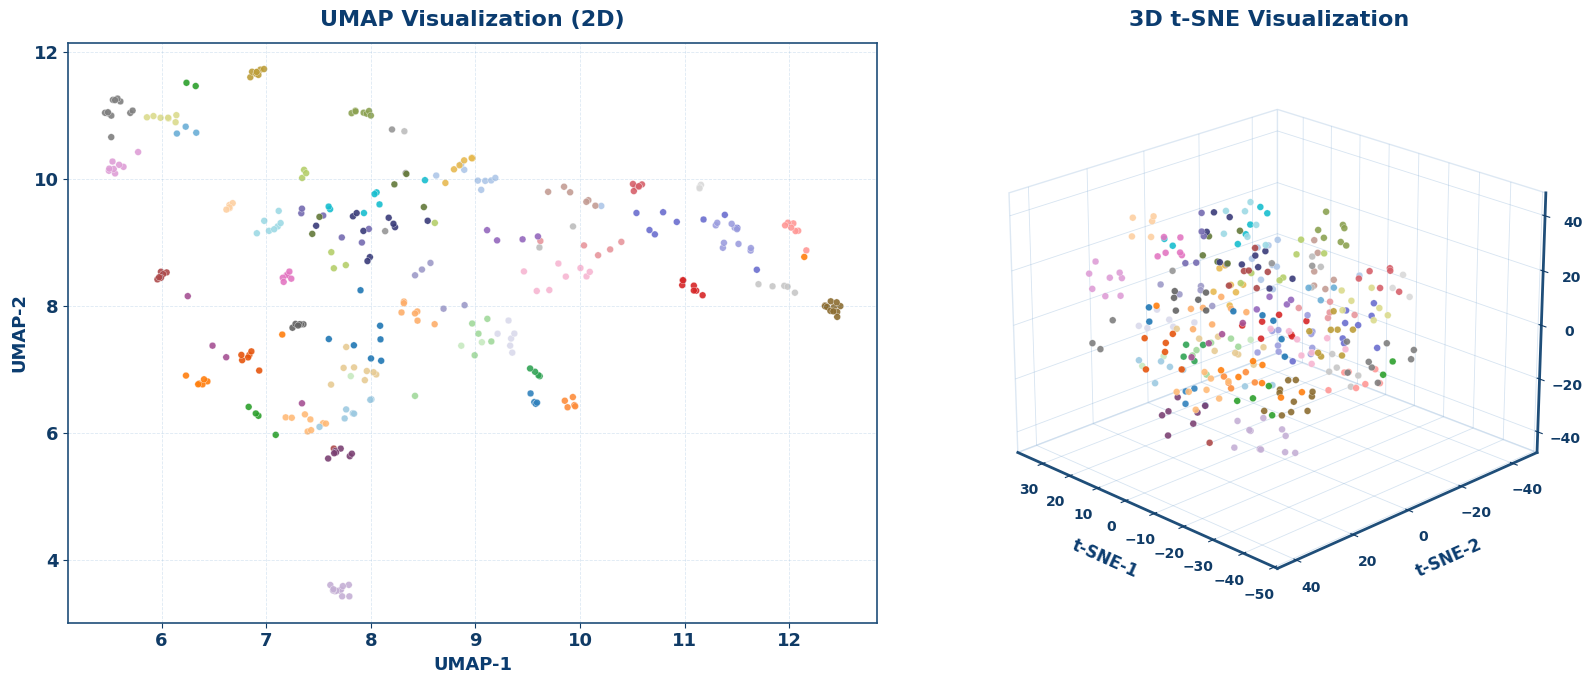

Saved: /kaggle/working/plots_transformer_mlp_xai_1536/umap_2d_and_tsne_3d_multicolor.png


In [18]:
# ============================================================
# UMAP (2D) + 3D t-SNE visualization for 1536 fused features
# White background + distinguishable class colors
# Single plot / single runnable cell
# Compatible with your Transformer + MLP Head pipeline
# ============================================================

import sys
import subprocess
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import ListedColormap

from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

# -------------------------
# Install UMAP if needed
# -------------------------
def ensure_umap():
    try:
        import umap  # noqa
    except Exception:
        print("Installing umap-learn ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "umap-learn"])

ensure_umap()
import umap

# =========================
# PATHS
# =========================
SPLIT_DIR = Path("/kaggle/working/features/closed_set_splits")

TEST_FILE = SPLIT_DIR / "test_closedset_70_15_15.npz"

OUT_DIR = Path("/kaggle/working/plots_transformer_mlp_xai_1536")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# =========================
# LOAD TEST DATA
# =========================
Dte = np.load(TEST_FILE, allow_pickle=True)

X_test = Dte["X"].astype(np.float32)
y_test = Dte["y"]

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# =========================
# SELECT DATA FOR VISUALIZATION
# =========================
X_vis = X_test
y_vis = y_test

MAX_POINTS = 2000
rng = np.random.RandomState(42)

if len(X_vis) > MAX_POINTS:
    idx = rng.choice(len(X_vis), size=MAX_POINTS, replace=False)
    X_vis = X_vis[idx]
    y_vis = y_vis[idx]

print("Using samples:", len(X_vis))

# =========================
# SCALE FEATURES
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_vis)

# =========================
# UMAP -> 2D
# =========================
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=20,
    min_dist=0.05,
    metric="euclidean",
    random_state=42
)
X_umap = umap_model.fit_transform(X_scaled)

# =========================
# 3D t-SNE
# =========================
tsne_3d = TSNE(
    n_components=3,
    perplexity=40,
    learning_rate="auto",
    init="pca",
    random_state=42,
    max_iter=1500
)
X_tsne_3d = tsne_3d.fit_transform(X_scaled)

# =========================
# WHITE STYLE SETTINGS
# =========================
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#1f4e79",
    "axes.labelcolor": "#103b66",
    "xtick.color": "#103b66",
    "ytick.color": "#103b66",
    "text.color": "#103b66",
    "font.size": 12
})

# =========================
# BETTER MULTI-CLASS COLORMAP
# =========================
colors1 = plt.cm.tab20(np.linspace(0, 1, 20))
colors2 = plt.cm.tab20b(np.linspace(0, 1, 20))
colors3 = plt.cm.tab20c(np.linspace(0, 1, 20))
all_colors = np.vstack([colors1, colors2, colors3])
custom_cmap = ListedColormap(all_colors)

# remap labels to 0...C-1 for stable coloring
unique_labels = np.unique(y_vis)
label_to_idx = {lab: i for i, lab in enumerate(unique_labels)}
y_vis_mapped = np.array([label_to_idx[v] for v in y_vis])

# =========================
# SINGLE FIGURE: UMAP + 3D t-SNE
# =========================
fig = plt.figure(figsize=(17, 7), facecolor="white")

# ---- Left: UMAP 2D
ax1 = fig.add_subplot(1, 2, 1)
sc1 = ax1.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=y_vis_mapped,
    cmap=custom_cmap,
    s=24,
    alpha=0.9,
    edgecolors="white",
    linewidths=0.25
)

ax1.set_title("UMAP Visualization (2D)", fontsize=16, fontweight="bold", color="#0b3c6f", pad=12)
ax1.set_xlabel("UMAP-1", fontsize=13, fontweight="bold", color="#0b3c6f")
ax1.set_ylabel("UMAP-2", fontsize=13, fontweight="bold", color="#0b3c6f")
ax1.grid(True, linestyle="--", linewidth=0.6, alpha=0.25, color="#7aa6d1")

for spine in ax1.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color("#1f4e79")

# ---- Right: t-SNE 3D
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
p = ax2.scatter(
    X_tsne_3d[:, 0],
    X_tsne_3d[:, 1],
    X_tsne_3d[:, 2],
    c=y_vis_mapped,
    cmap=custom_cmap,
    s=24,
    alpha=0.9,
    edgecolors="white",
    linewidths=0.2
)

ax2.set_title("3D t-SNE Visualization", fontsize=16, fontweight="bold", color="#0b3c6f", pad=12)
ax2.set_xlabel("t-SNE-1", fontsize=12, fontweight="bold", color="#0b3c6f", labelpad=8)
ax2.set_ylabel("t-SNE-2", fontsize=12, fontweight="bold", color="#0b3c6f", labelpad=8)
ax2.set_zlabel("t-SNE-3", fontsize=12, fontweight="bold", color="#0b3c6f", labelpad=8)

ax2.xaxis.pane.set_facecolor((1.0, 1.0, 1.0, 1.0))
ax2.yaxis.pane.set_facecolor((1.0, 1.0, 1.0, 1.0))
ax2.zaxis.pane.set_facecolor((1.0, 1.0, 1.0, 1.0))

ax2.xaxis.pane.set_edgecolor("#bcd2e8")
ax2.yaxis.pane.set_edgecolor("#bcd2e8")
ax2.zaxis.pane.set_edgecolor("#bcd2e8")

try:
    ax2.xaxis._axinfo["grid"]["color"] = (0.48, 0.65, 0.82, 0.30)
    ax2.yaxis._axinfo["grid"]["color"] = (0.48, 0.65, 0.82, 0.30)
    ax2.zaxis._axinfo["grid"]["color"] = (0.48, 0.65, 0.82, 0.30)
    ax2.xaxis._axinfo["grid"]["linewidth"] = 0.6
    ax2.yaxis._axinfo["grid"]["linewidth"] = 0.6
    ax2.zaxis._axinfo["grid"]["linewidth"] = 0.6
except Exception:
    pass

ax2.tick_params(labelsize=10, colors="#103b66")
ax2.view_init(elev=22, azim=135)

plt.tight_layout()

# =========================
# SAVE
# =========================
out_path = OUT_DIR / "umap_2d_and_tsne_3d_multicolor.png"
plt.savefig(out_path, dpi=1200, bbox_inches="tight", facecolor="white")
plt.show()

print("Saved:", out_path)